# Imputation study on the expanded synthetic dataset

**PGS219 · measured/truth file pairs · out-of-fold evaluation**

The synthetic data lets us set the noise, the missingness and the relationships between columns in advance. This notebook uses that control to ask three questions:

1. **Do the models identify the relationships built into the data?**
2. **When do they fail?** Across noise, missing inputs and removed predictors.
3. **How do the methods compare?** On accuracy, preserved distributions, stability and cost.

Models receive measured data only and no description of the relationships. Truth is read only after fitting, for scoring. These results describe this synthetic dataset and do not establish performance on real SA Power Networks assets.

**To run:** create the environment once, select the kernel **Python (imputation)**, then Restart and Run All.

```
conda create -n imputation python=3.12
conda activate imputation
pip install -r requirements.txt
python -m ipykernel install --user --name imputation --display-name "Python (imputation)"
```

## 1. Setup

`QUICK = True` runs every stage on a small sample with small models, as a check that the notebook works; its numbers are not findings. To continue an interrupted run, set `RESUME_RUN_ID` to its folder name. A resumed run is refused if the data, the configuration or the study code has changed.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / "src/team19_asset_data").is_dir():
    ROOT = ROOT.parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
# A kernel left open keeps earlier versions of these modules, so they are always reloaded.
for name in [m for m in sys.modules if m.startswith("team19_asset_data.imputation_study")]:
    del sys.modules[name]

from team19_asset_data.imputation_study import evaluation as ev
from team19_asset_data.imputation_study import figures as fg
from team19_asset_data.imputation_study.columns import NUMERIC_TARGETS, TARGETS, column_table
from team19_asset_data.imputation_study.data import (
    audit_design, audit_fields, audit_files, discover, read_truth, relationship_residuals,
)
from team19_asset_data.imputation_study.models import CATEGORY_METHODS, NUMERIC_METHODS
from team19_asset_data.imputation_study.runner import (
    StudyConfig, build_plan, build_tuning_plan, default_workers, plan_table, quick_config,
)
from team19_asset_data.imputation_study.study import Study
from team19_asset_data.transformers.miceforest_compat import require_supported_version

QUICK = False
RESUME_RUN_ID = None
WORKERS = default_workers()

CONFIG = quick_config() if QUICK else StudyConfig()
ALL_SCENARIOS = discover(ROOT / CONFIG.data_directory)
SCENARIOS = {name: ALL_SCENARIOS[name] for name in (CONFIG.scenarios or sorted(ALL_SCENARIOS))}
REPRESENTATIVE = CONFIG.representative
NOISE_FREE, HIGH_NOISE = CONFIG.noise_series[0], CONFIG.noise_series[-1]

require_supported_version()
fg.apply_style()
pd.set_option("display.max_columns", None, "display.max_colwidth", 140, "display.width", 200,
              "display.max_rows", 200)
print("Mode:", "QUICK CHECK, not findings" if QUICK else "full study")
print("Scenarios:", len(SCENARIOS), "| worker processes:", WORKERS)


Mode: full study
Scenarios: 9 | worker processes: 12


## 2. The dataset

### 2.1 How the data is built

The files describe 10,000 assets on a 100 × 100 grid, generated row by row in grid order. Installation days increase along that order. Each asset has a model, environmental exposures, three gas levels, a leakage rate and a remaining-life value. Each scenario has two tables:

- **truth**: the values before measurement error and before any cell is hidden.
- **measured**: the table a model sees, with measurement error and hidden cells.

The file name sets two controls. `completion` is the chance that a cell stays visible; hiding is independent for every cell in every column, so the data is missing completely at random. `noise` is the bound of a uniform multiplicative error on the columns that are measured: `noise0.05` means a reading can be off by up to ±5%.

All nine scenarios describe the same assets. A cell keeps one noise draw, scaled by the noise level, and one mask draw, compared with the completion level. A change between two scenarios therefore comes from that control alone and can be measured on the same cells.

### 2.2 What each column means and how it is treated

These decisions follow from what a column represents: its type, its measurement scale, its valid range and how it is measured. They do not depend on patterns in the data.

In [2]:
with pd.option_context("display.max_colwidth", None):
    display(column_table())


,column,meaning,family,unit,scale,noisy,valid range,tolerance,treatment
0,x,Grid row of the asset location,location and date,grid cells,interval,no,0 to 99,±1 and ±5 grid cells,"Numeric coordinate, not a category. Predictions stay on the grid (rounded, 0-99). The zero point is arbitrary, so tolerance is in cells rather than percent."
1,y,Grid column of the asset location,location and date,grid cells,interval,no,0 to 99,±1 and ±5 grid cells,Same treatment as x.
2,install_date,"Installation day, counted from the start of the sequence",location and date,days,interval,no,0 to -,±7 and ±30 days,"Whole-day counter with no calendar origin, so it stays a number and is not converted to age. The origin is arbitrary, so tolerance is in days rather than percent."
3,model_id,Transformer model,asset condition,category,nominal,no,- to -,exact class,"Nominal label: the numbers 0-3 have no order. One-hot encoded as a predictor, with missing as its own level, and classified as a target. Never regressed or rounded."
4,altitude,Ground altitude at the location,location and date,synthetic units,interval,no,100 to 298,±1 and ±5 synthetic units,"Whole-number field limited to the range the grid can produce (100-298). Its zero point does not compare assets, so tolerance is in units rather than percent."
5,measured_humid,Humidity exposure reading,field reading,index,ratio,yes,0 to 1,±10% and ±15%,"Noisy reading between 0 and 1 with a true zero, so percent tolerance is valid. Predictions are limited to that range. Scored against the noise-free truth."
6,measured_salt,Salt exposure reading,field reading,index,ratio,yes,0 to 1,±10% and ±15%,Same treatment as measured_humid.
7,measured_overgrowth,Vegetation overgrowth reading,field reading,index,ratio,yes,0 to 2,±10% and ±15%,"Floored at zero by definition, so exact zeros are real readings, not missing data. Percent tolerance cannot apply to a true zero; zero and positive cells are evaluated separately."
8,life,Remaining-life indicator,asset condition,synthetic units,ratio,no,0 to 100000,±100 and ±500 synthetic units,"Exact asset outcome. It sits in a narrow band just under its ceiling, where ±10% would accept almost any value, so tolerance is in units. Predictions cannot exceed the ceiling."
9,random_placebo,Random number unrelated to any other column,control,index,ratio,yes,0 to 1,±10% and ±15%,"Negative control, limited to 0-1. It is imputed and scored like any target, but any real gain over the median would be a false finding."


Why tolerances differ between columns:

- **Coordinates, days and altitude** have an arbitrary zero point, so ±10% would mean different things at different positions. They use absolute limits.
- **`life`** sits in a narrow band below its ceiling, where ±10% would accept almost any value. It also uses absolute limits.
- **Humidity, salt, overgrowth and the placebo** have a true zero and a wide relative range, so percent limits apply.
- **Gas columns and `leakage`** vary less, so their percent limits are tighter. `total_gas` varies least and has the tightest limits.

### 2.3 File audit

The audit checks the files against their definitions: the shape of each pair, how much of each column is observed, and whether measurement error stays inside the bound in the file name. `measurement MAE` is the error already present in observed cells. Noisy columns are scored against truth, so this shows how far a reading itself sits from the truth.

,scenario,completion,noise,rows,columns,missing share,columns with missing cells
0,completion0.7-noise0.0,0.7,0.00,10000,15,0.2997,15
1,completion0.7-noise0.05,0.7,0.05,10000,15,0.2997,15
2,completion0.7-noise0.1,0.7,0.10,10000,15,0.2997,15
3,completion0.8-noise0.0,0.8,0.00,10000,15,0.1995,15
4,completion0.8-noise0.05,0.8,0.05,10000,15,0.1995,15
5,completion0.8-noise0.1,0.8,0.10,10000,15,0.1995,15
6,completion0.9-noise0.0,0.9,0.00,10000,15,0.0995,15
7,completion0.9-noise0.05,0.9,0.05,10000,15,0.0995,15
8,completion0.9-noise0.1,0.9,0.10,10000,15,0.0995,15


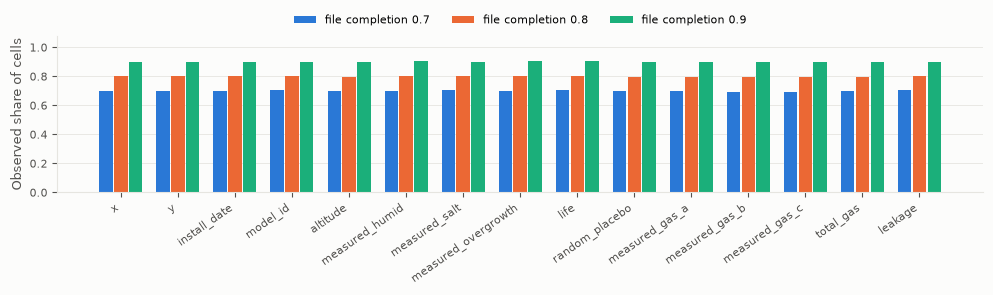

In [3]:
FILE_AUDIT = audit_files(ALL_SCENARIOS)
FIELD_AUDIT = audit_fields(ALL_SCENARIOS)
display(FILE_AUDIT.round(4))
fg.plot_missingness(FIELD_AUDIT, None)


In [4]:
noise_check = FIELD_AUDIT.groupby(["column", "noise"], sort=False).agg(
    changed=("changed share", "mean"),
    largest=("largest relative change", "max"),
    measurement_mae=("measurement MAE", "mean"),
).unstack("noise")
display(noise_check.round(4))

noise_free = FIELD_AUDIT[FIELD_AUDIT.noise.eq(0)]
inside_bound = (FIELD_AUDIT["largest relative change"] <= FIELD_AUDIT.noise + 1e-9).all()
never_noisy = FIELD_AUDIT[~FIELD_AUDIT["defined as noisy"]]["changed share"].eq(0).all()
print("Noise-free files equal the truth in every observed cell:", noise_free["changed share"].eq(0).all())
print("Every measured value lies inside the bound in its file name:", inside_bound)
print("Columns defined without noise are unchanged in every file:", never_noisy)


changed                 largest            measurement_mae                    
noise                  0.00    0.05    0.10    0.00  0.05 0.10            0.00      0.05      0.10
column                                                                                            
x                       0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
y                       0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
install_date            0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
model_id                0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
altitude                0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
measured_humid          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0    0.0083    0.0166
measured_salt           0.0  1.0000  1.0000     0.0  0.05  0.1             0.0    0.0104    0.0208
measured_overgrowth     0.0  0.6773  0.6773     0.0  0.05  0.1             0.0    0.0083    0.0167
life                    0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
random_placebo          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0    0.0125    0.0251
measured_gas_a          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0  233.2870  466.5740
measured_gas_b          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0  243.3178  486.6355
measured_gas_c          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0  233.6805  467.3610
total_gas               0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
leakage                 0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000

Noise-free files equal the truth in every observed cell: True
Every measured value lies inside the bound in its file name: True
Columns defined without noise are unchanged in every file: True


The next two tables confirm that scenarios can be compared cell by cell, and that the truth follows the generator's definitions.

In [5]:
with pd.option_context("display.max_colwidth", None):
    display(audit_design(ALL_SCENARIOS))
display(relationship_residuals(read_truth(ALL_SCENARIOS[REPRESENTATIVE])))


,property,holds
0,Every file has the same truth,True
1,A completeness level hides the same cells at every noise level,True
2,Cells hidden at higher completeness are also hidden at lower completeness,True


,definition,largest residual
0,altitude = x + y + 100,0.000000e+00
1,"overgrowth = max(2 humid - salt, 0)",4.440892e-16
2,total_gas = gas a + b + c,1.273293e-11
3,life follows the formula of the row's model,4.365575e-11


### 2.4 Generator decisions

The dataset was regenerated after review with the generator's author. The earlier version is kept in `data/datasets_v1`.

- **Masking** covers all 15 columns. The first version covered only the first eight.
- **Noise** applies only to humidity, salt, overgrowth, the placebo and the three gas readings. `life`, `total_gas` and `leakage` are exact by design, so some columns stay reliable when others degrade.
- **Gas and `life`**: more gas reduces `life` for every model. The scale `total_gas/300000` is kept from the first version, so this term is small.
- **Model 0** uses `day_count` in its overgrowth term, matching the other models. The first version used an undefined variable.
- **Missingness** is completely at random only. The generator does not explore other mechanisms.

## 3. Experimental design

### 3.1 Targets and predictors

Every column has missing cells, so all 15 are imputation targets: 14 numeric columns and `model_id`. `random_placebo` is one of them and serves as the negative control. For each target, every other column is a predictor. Predictors keep their original gaps, and no extra masking or noise is added.

### 3.2 Preprocessing shared by all models

All fitted values, including means, scales and category levels, come from the training fold.

| Step | Decision | Reason |
|---|---|---|
| Missing predictors | Left as missing | Each method handles gaps natively, so no values are invented before the model sees them. |
| Missing indicators | Not used | Masks are random, so an indicator carries no information about the value. |
| `model_id` as a predictor | One-hot, with missing as a separate level | It is nominal, so its numbers must not be read as an order. |
| Row position | Never a feature | It would reveal the grid position, and it is not a property of an asset. |
| Predictions | Limited to the valid range; whole-number columns rounded | Follows from the column definitions. The raw value is kept, and section 5 reports how often this applied. |

### 3.3 Tuning

Each model's settings are chosen before its experiments, on the representative scenario:

- A random sample of settings, plus the earlier study's settings, is scored by cross-validation for each target.
- Scoring uses **observed labels only**. Truth and the hidden cells play no part, so the evaluation stays out of sample.
- The loss is MAE for numeric targets and log loss for `model_id`, because accuracy alone cannot separate near-perfect models.
- The chosen settings are then fixed for every scenario, so a change between scenarios is not caused by a change of settings.

The settings suit the representative scenario best and may not be the best for every scenario. Labels there contain noise, so tuning aims at the measured values rather than the truth.

### 3.4 Evaluation

Five folds are shared by all methods within a seed. A hidden cell is predicted by a model that never saw its row, and it is scored against the truth.

| Measure | Used for |
|---|---|
| MAE, RMSE, R², bias | Size and direction of error, in the column's own unit |
| Skill | Share of the median's MAE removed: 0 matches the median, 1 is perfect, below 0 is worse |
| Tolerance rate | Share within the column's tight and loose limits from section 2.2 |
| Exact rate | Share of whole-number columns recovered exactly |
| Tuning change | Change in MAE from the earlier study's settings to the tuned settings, on the same cells |
| Accuracy, macro F1, balanced accuracy | `model_id`; log loss, Brier score and calibration gap for its probabilities |

MAE values are never averaged across columns because their units differ.

### 3.5 Experiments

In [6]:
TUNING_PLAN = build_tuning_plan(CONFIG)
PLAN = build_plan(list(SCENARIOS), CONFIG)
display(plan_table(TUNING_PLAN + PLAN))
print("Planned tasks:", len(TUNING_PLAN) + len(PLAN))


,experiment,tasks,scenarios,seeds,methods
0,tuning,945,1,1,6
1,main,4095,9,1,9
2,stability,910,1,2,9
3,defaults,375,1,1,6
4,budget,10,1,1,2
5,pmm,70,1,1,1
6,joint,5,1,1,1
7,calibration,10,1,1,1
8,ablation,2310,3,1,5
9,importance,90,3,1,2


Planned tasks: 8820


- **tuning**: settings search on observed labels.
- **main**: every target and method in every scenario.
- **stability**: the representative scenario with two more fold seeds.
- **defaults**: the earlier study's settings, for comparison with tuned settings.
- **budget**: IterativeImputer stopped early, to show what convergence adds.
- **pmm** and **joint**: repeated imputations in the representative scenario.
- **calibration**: Random Forest with calibrated probabilities for `model_id`, with all predictors and without the gas columns.
- **ablation**: refits without a block of predictors, across the three noise levels at 0.8 completion. Targets inside the removed block are skipped.
- **importance**: permutation importance on held-out observed labels.

## 4. Models

Each model has its own section: how it works, how it is set up for this data, then its run and results. Sections run in order, starting with the baselines, because skill is measured against the median. Finished tasks are saved immediately, so an interruption loses only the tasks in progress. Model code never reads truth.

The representative scenario is `completion0.8-noise0.05`: moderate missingness and moderate noise.

In [7]:
STUDY = Study(ROOT, CONFIG, SCENARIOS, WORKERS, RESUME_RUN_ID)
print("Run folder:", STUDY.directory)


Run folder: C:\Users\Morgan\Desktop\Capstone Project\gh\team19-asset-data\outputs\imputation-study\runs\20261105-133845


### 4.1 Median and Mode

The baselines fill every hidden cell with one value from the training fold: the median for numeric targets and the most common class for `model_id`. They use no other column, so they cannot learn any relationship.

**Setup:** nothing to tune or scale.

**What to look for:** every other model must beat these to show it has learned something. On `random_placebo`, the median is the correct answer.

In [8]:
STUDY.run_model("Median and Mode")
STUDY.show_model("Median and Mode")


Experiments: 825 tasks
82/825 tasks, 3 s
164/825 tasks, 3 s
246/825 tasks, 3 s
328/825 tasks, 3 s
410/825 tasks, 3 s
492/825 tasks, 3 s
574/825 tasks, 4 s
656/825 tasks, 4 s
738/825 tasks, 4 s
820/825 tasks, 4 s
825/825 tasks, 4 s


**Median · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,24.8884,28.7428,-0.0006,0.1658,0.0,0.0302,0.1085,0.0116
1,y,25.3187,29.0652,-0.0009,0.0348,0.0,0.0268,0.1010,0.0071
2,install_date,343.3320,397.3921,-0.0005,3.2955,0.0,0.0127,0.0471,0.0010
3,altitude,33.8737,41.2782,-0.0022,1.8260,0.0,0.0269,0.0930,0.0094
4,measured_humid,0.1730,0.2083,-0.0066,-0.0169,0.0,0.1048,0.1562,NaN
5,measured_salt,0.2117,0.2475,-0.0022,-0.0116,0.0,0.1029,0.1501,NaN
6,measured_overgrowth,0.3008,0.3821,-0.0954,-0.1128,0.0,0.0467,0.0720,NaN
7,life,290.0439,392.9534,-0.0423,79.0972,0.0,0.2329,0.8304,NaN
8,random_placebo,0.2530,0.2911,-0.0021,0.0126,0.0,0.1034,0.1502,NaN
9,measured_gas_a,1247.7975,1450.9424,-0.0505,-317.5190,0.0,0.0597,0.3916,NaN


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
4,Mode,1965,0.2809,0.1774,0.2483


,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,Median,630,5.793,0.770,0.010
1,Mode,45,0.450,0.053,0.011


Tasks: 825 | failed: 0 | with warnings: 0


### 4.2 K-nearest neighbours

KNN finds the rows most similar to the one being filled and averages their values, or takes a weighted vote for `model_id`. It assumes nothing about the form of a relationship: a row is informative only if similar rows exist.

**Setup:** columns are scaled so that no unit dominates the distance. Distances use only the cells two rows both have, so gaps need no filling. `KNNImputer` handles numeric targets and `KNeighborsClassifier` handles `model_id`. Tuning chooses the number of neighbours and the weighting.

**What to look for:** every column counts equally in the distance, including ones unrelated to the target such as `random_placebo`. Accuracy should suffer most for targets driven by few columns.

Tuning: 165 candidates
16/165 tasks, 27 s
32/165 tasks, 41 s
48/165 tasks, 55 s
64/165 tasks, 79 s
80/165 tasks, 93 s
96/165 tasks, 108 s
112/165 tasks, 132 s
128/165 tasks, 146 s
144/165 tasks, 160 s
160/165 tasks, 173 s
165/165 tasks, 174 s
Experiments: 1650 tasks
165/1650 tasks, 17 s
330/1650 tasks, 29 s
495/1650 tasks, 37 s
660/1650 tasks, 41 s
825/1650 tasks, 51 s
990/1650 tasks, 60 s
1155/1650 tasks, 69 s
1320/1650 tasks, 78 s
1485/1650 tasks, 87 s
1650/1650 tasks, 96 s


**Tuning** (cross-validated loss on observed labels)

,method,targets,targets changed,largest loss reduction
0,KNN,1,1,-0.2941
1,KNN imputer,14,14,-0.1260


,target,method,settings
0,x,KNN imputer,"{""n_neighbors"": 10, ""weights"": ""distance""}"
1,y,KNN imputer,"{""n_neighbors"": 20, ""weights"": ""distance""}"
2,install_date,KNN imputer,"{""n_neighbors"": 10, ""weights"": ""distance""}"
3,altitude,KNN imputer,"{""n_neighbors"": 40, ""weights"": ""uniform""}"
4,measured_humid,KNN imputer,"{""n_neighbors"": 20, ""weights"": ""distance""}"
5,measured_salt,KNN imputer,"{""n_neighbors"": 20, ""weights"": ""distance""}"
6,measured_overgrowth,KNN imputer,"{""n_neighbors"": 40, ""weights"": ""uniform""}"
7,life,KNN imputer,"{""n_neighbors"": 20, ""weights"": ""uniform""}"
8,random_placebo,KNN imputer,"{""n_neighbors"": 40, ""weights"": ""uniform""}"
9,measured_gas_a,KNN imputer,"{""n_neighbors"": 20, ""weights"": ""distance""}"


**KNN imputer · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact,tuning change
0,x,4.7884,6.4480,0.9496,-0.1191,0.8076,0.2055,0.6729,0.0653,-0.0239
1,y,15.3535,19.1779,0.5643,-0.5434,0.3936,0.0616,0.2202,0.0157,-0.0458
2,install_date,63.6477,84.2119,0.9551,-9.0507,0.8146,0.0791,0.3071,0.0035,-0.0326
3,altitude,14.3297,18.3465,0.8020,-1.3590,0.5770,0.0811,0.2606,0.0254,-0.1268
4,measured_humid,0.0978,0.1232,0.6479,-0.0125,0.4345,0.2157,0.3246,NaN,-0.0741
5,measured_salt,0.1694,0.2038,0.3208,0.0072,0.1999,0.1511,0.2181,NaN,-0.0383
6,measured_overgrowth,0.1384,0.1795,0.7584,-0.0127,0.5399,0.2008,0.3172,NaN,-0.1203
7,life,117.3110,178.4102,0.7851,12.6080,0.5955,0.6067,0.9745,NaN,-0.1229
8,random_placebo,0.2567,0.2959,-0.0357,0.0108,-0.0144,0.0990,0.1402,NaN,-0.0504
9,measured_gas_a,216.9199,355.5845,0.9369,3.4863,0.8262,0.9104,0.9692,NaN,-0.0974


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
8,KNN,1965,0.974,0.9726,0.973


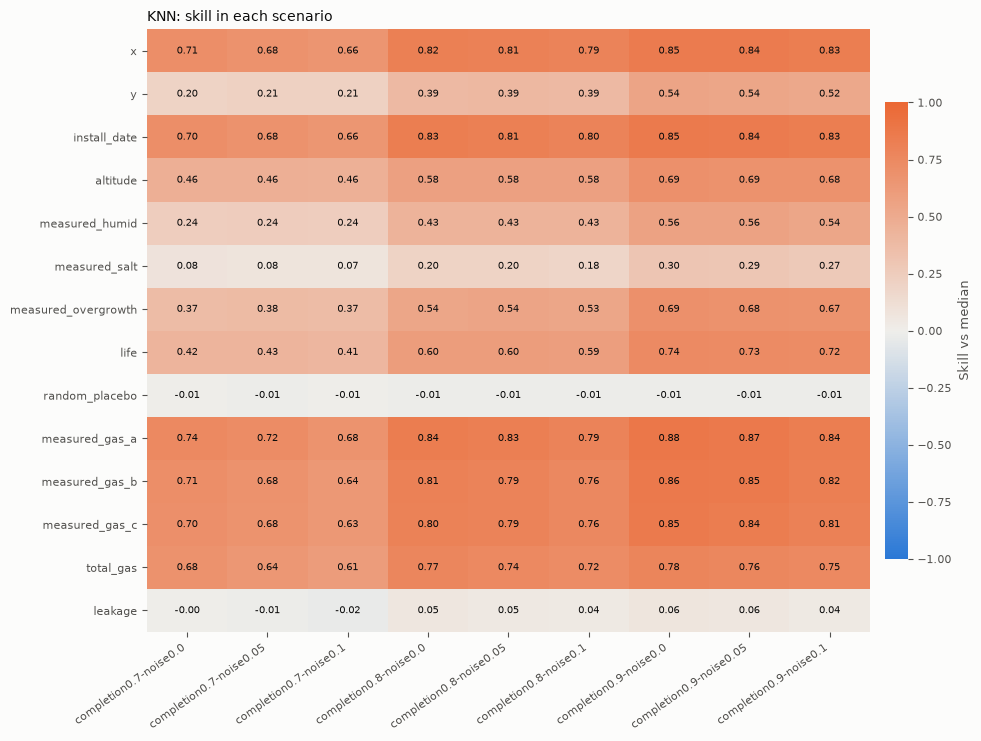

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
KNN,0.9522,0.9262,0.8669,0.9781,0.974,0.9415,0.999,0.997,0.9769


,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,KNN imputer,630,12.724,456.400,0.745
1,KNN,45,0.897,11.625,0.278


Tasks: 1650 | failed: 0 | with warnings: 0


In [9]:
STUDY.run_model("KNN")
STUDY.show_model("KNN")


### 4.3 IterativeImputer

IterativeImputer fills each column with a Bayesian ridge regression on the others, then repeats, using the latest estimates of the other columns each time. It imputes every numeric column in one fit, so a hidden cell can draw on estimates of other hidden cells in the same row.

**Setup:** columns are scaled, and `model_id` enters as one-hot columns. Each regression is linear, so this model can represent additive relationships exactly but cannot represent thresholds or interactions. It imputes numbers only, so it has no `model_id` result. It has no search space: the setting that matters is the number of iterations, which is decided by convergence, up to a limit of 2,000.

**What to look for:** strength on the additive relationships and weakness on the overgrowth threshold and on `life`, which depends on interactions.

Experiments: 125 tasks
12/125 tasks, 110 s
24/125 tasks, 160 s
36/125 tasks, 182 s
48/125 tasks, 216 s
60/125 tasks, 236 s
72/125 tasks, 260 s
84/125 tasks, 282 s
96/125 tasks, 297 s
108/125 tasks, 318 s
120/125 tasks, 326 s
125/125 tasks, 349 s


**IterativeImputer · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,1.0588,4.0779,0.9799,0.1724,0.9575,0.9020,0.9452,0.8201
1,y,5.8136,14.9506,0.7352,-0.1793,0.7704,0.7722,0.8020,0.7187
2,install_date,27.3877,73.2480,0.9660,3.7790,0.9202,0.7750,0.8241,0.1100
3,altitude,5.9503,15.0969,0.8659,-0.0149,0.8243,0.7514,0.7961,0.7220
4,measured_humid,0.0702,0.0944,0.7932,-0.0005,0.5943,0.3251,0.4501,NaN
5,measured_salt,0.1297,0.1695,0.5301,0.0023,0.3877,0.2170,0.3017,NaN
6,measured_overgrowth,0.0827,0.1259,0.8811,0.0164,0.7249,0.3709,0.4935,NaN
7,life,140.3048,185.3162,0.7682,-1.9304,0.5163,0.4622,0.9826,NaN
8,random_placebo,0.2531,0.2911,-0.0020,0.0122,-0.0002,0.1029,0.1487,NaN
9,measured_gas_a,283.3885,403.9452,0.9186,4.6039,0.7729,0.8184,0.9633,NaN


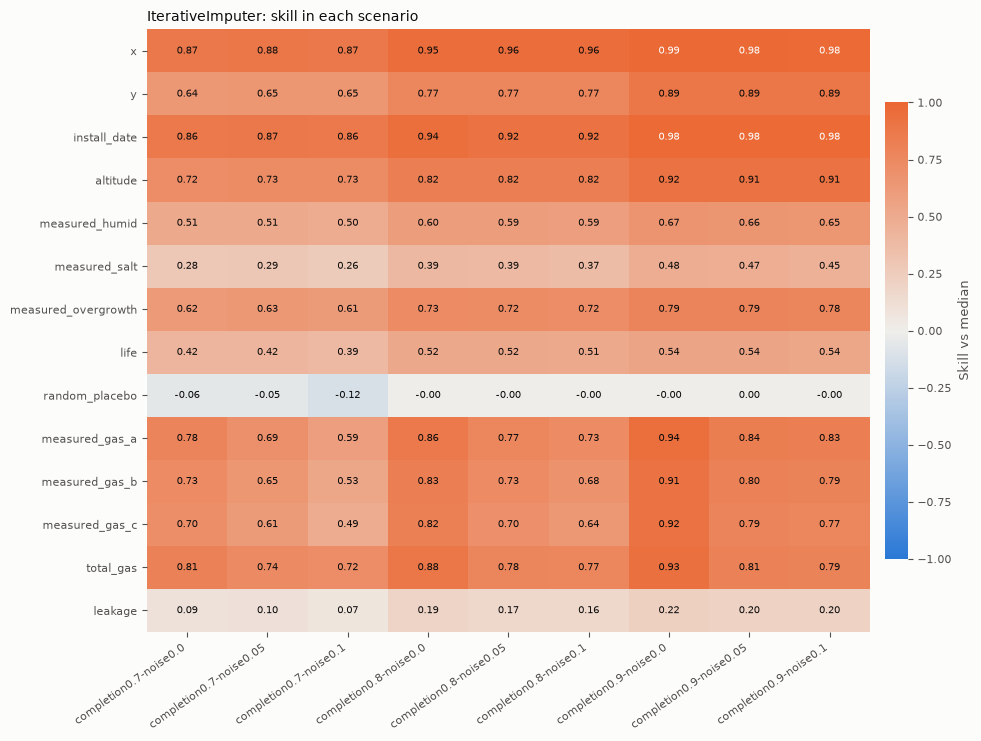

,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,IterativeImputer,45,2793.256,52.386,4.517


Tasks: 125 | failed: 0 | with warnings: 12


In [10]:
STUDY.run_model("IterativeImputer")
STUDY.show_model("IterativeImputer")


**Convergence.** The first table shows what stopping early costs on the same cells; the earlier study stopped at 10 iterations. The second shows the iterations used in each scenario. A fit stopped at the limit has not converged. Convergence does not by itself show that the imputed values are accurate.

In [11]:
iterative_numeric, _ = STUDY.scores_for("IterativeImputer")
budget, iterations = ev.budget_table(iterative_numeric, STUDY.logs["IterativeImputer"], STUDY.config)
display(budget.round(4))
display(iterations)


,MAE at limit 10,MAE at limit 30,MAE at limit 2000
target,,,
x,1.5764,1.1342,1.0588
y,5.9990,5.8359,5.8136
install_date,27.5540,24.5819,27.3877
altitude,6.0915,5.9592,5.9503
measured_humid,0.0700,0.0701,0.0702
measured_salt,0.1292,0.1295,0.1297
measured_overgrowth,0.0825,0.0826,0.0827
life,139.7372,139.8243,140.3048
random_placebo,0.2531,0.2531,0.2531


,scenario,fits,fewest iterations,most iterations,fits stopped at the limit
0,completion0.7-noise0.0,5,585,1834,0
1,completion0.7-noise0.05,5,303,2000,1
2,completion0.7-noise0.1,5,280,2000,1
3,completion0.8-noise0.0,5,64,216,0
4,completion0.8-noise0.05,5,56,199,0
5,completion0.8-noise0.1,5,52,200,0
6,completion0.9-noise0.0,5,44,85,0
7,completion0.9-noise0.05,5,43,83,0
8,completion0.9-noise0.1,5,40,88,0


### 4.4 Random Forest

Random Forest averages many deep decision trees, each grown on a bootstrap sample of the rows. Averaging reduces the noise of single trees, and trees capture thresholds and interactions without being told about them.

**Setup:** no scaling, since splits depend only on order. Gaps are handled by the trees themselves. Tuning chooses the minimum leaf size and how many columns each split considers. The number of trees stays at 200.

**What to look for:** trees approximate a straight-line relationship with steps, so exact sums such as altitude should be recovered closely but not exactly. An averaged forest also cannot predict outside the range of its training labels.

Tuning: 195 candidates
19/195 tasks, 15 s
38/195 tasks, 28 s
57/195 tasks, 42 s
76/195 tasks, 56 s
95/195 tasks, 69 s
114/195 tasks, 84 s
133/195 tasks, 100 s
152/195 tasks, 115 s
171/195 tasks, 130 s
190/195 tasks, 143 s
195/195 tasks, 147 s
Experiments: 1705 tasks
170/1705 tasks, 70 s
340/1705 tasks, 135 s
510/1705 tasks, 209 s
680/1705 tasks, 290 s
850/1705 tasks, 365 s
1020/1705 tasks, 439 s
1190/1705 tasks, 497 s
1360/1705 tasks, 555 s
1530/1705 tasks, 612 s
1700/1705 tasks, 670 s
1705/1705 tasks, 673 s


**Tuning** (cross-validated loss on observed labels)

,method,targets,targets changed,largest loss reduction
0,Random Forest,15,9,-0.4109


,target,method,settings
0,x,Random Forest,"{""max_features"": 1.0, ""min_samples_leaf"": 2, ""n_estimators"": 200}"
1,y,Random Forest,"{""min_samples_leaf"": 2, ""n_estimators"": 200}"
2,install_date,Random Forest,"{""min_samples_leaf"": 2, ""n_estimators"": 200}"
3,altitude,Random Forest,"{""min_samples_leaf"": 2, ""n_estimators"": 200}"
4,measured_humid,Random Forest,"{""min_samples_leaf"": 2, ""n_estimators"": 200}"
5,measured_salt,Random Forest,"{""min_samples_leaf"": 2, ""n_estimators"": 200}"
6,measured_overgrowth,Random Forest,"{""max_features"": 0.7, ""min_samples_leaf"": 1, ""n_estimators"": 200}"
7,life,Random Forest,"{""max_features"": 0.7, ""min_samples_leaf"": 1, ""n_estimators"": 200}"
8,random_placebo,Random Forest,"{""max_features"": 0.33, ""min_samples_leaf"": 20, ""n_estimators"": 200}"
9,measured_gas_a,Random Forest,"{""max_features"": 0.7, ""min_samples_leaf"": 1, ""n_estimators"": 200}"


**Random Forest · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact,tuning change
0,x,1.1447,3.1543,0.9879,0.2141,0.9540,0.8261,0.9276,0.7437,0.0000
1,y,5.8273,12.3164,0.8203,-0.3687,0.7698,0.5227,0.7823,0.2227,0.0000
2,install_date,17.1612,45.0397,0.9871,0.7861,0.9500,0.7572,0.8490,0.2828,0.0000
3,altitude,5.8195,12.1971,0.9125,-0.1845,0.8282,0.4998,0.7802,0.2352,0.0000
4,measured_humid,0.0536,0.0817,0.8450,0.0020,0.6903,0.5066,0.5827,NaN,0.0000
5,measured_salt,0.1001,0.1452,0.6553,0.0022,0.5273,0.3742,0.4736,NaN,0.0000
6,measured_overgrowth,0.0633,0.1139,0.9027,0.0019,0.7896,0.5349,0.6238,NaN,-0.0036
7,life,71.2168,117.3859,0.9070,-6.7446,0.7545,0.7870,0.9928,NaN,-0.0173
8,random_placebo,0.2547,0.2930,-0.0152,0.0129,-0.0064,0.0985,0.1497,NaN,-0.0040
9,measured_gas_a,159.2698,274.5686,0.9624,-3.2862,0.8724,0.9662,0.9824,NaN,-0.0167


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
2,Random Forest,1965,0.9771,0.9758,0.9753


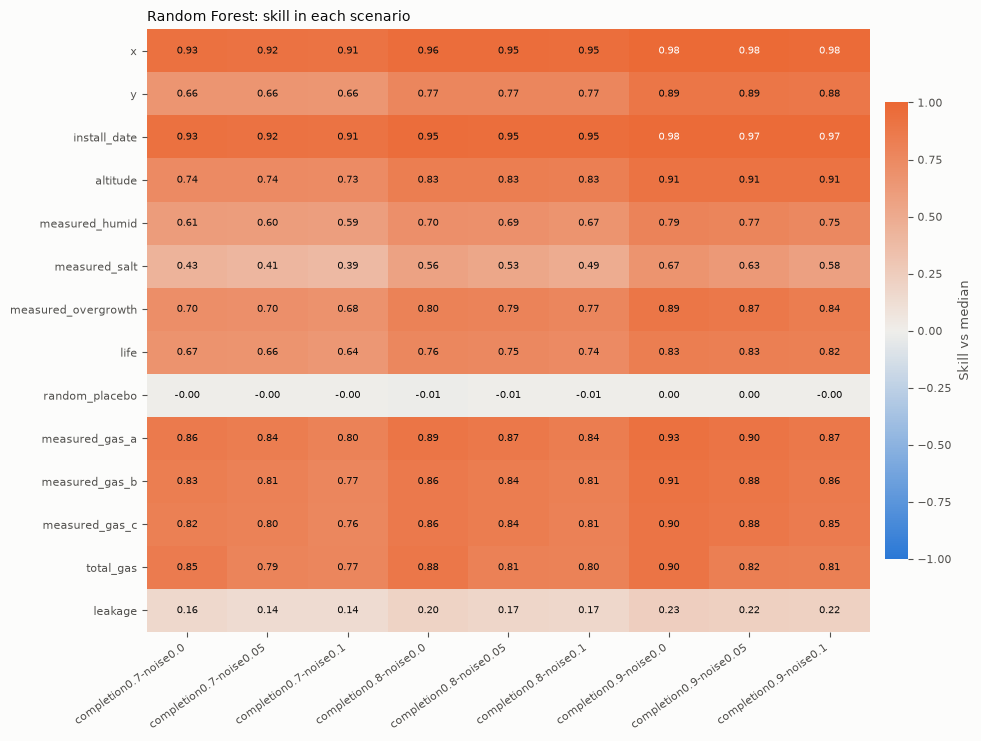

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
Random Forest,0.971,0.9653,0.9394,0.9832,0.9771,0.9634,0.999,0.999,0.9789


,method,tasks,fit seconds,predict seconds,seconds per target and fold
2,Random Forest,675,3400.908,15.892,5.062


Tasks: 1705 | failed: 0 | with warnings: 0


In [12]:
STUDY.run_model("Random Forest")
STUDY.show_model("Random Forest")


**Calibrated probabilities for `model_id`.** A confident prediction should be correct about as often as its probability says; the calibration gap measures the difference. The comparison is repeated without the gas columns because the task may otherwise be too easy to separate the methods. Calibration refits the forest on inner folds, so differences from the raw forest are not caused by the probability adjustment alone.

In [13]:
display(ev.probability_table(STUDY.scored["Random Forest"], STUDY.config).round(4))


,predictors,method,n,accuracy,log loss,Brier,calibration gap,accuracy of most confident 50%
2,all predictors,Random Forest,1965,0.9771,0.0462,0.0258,0.0115,1.0000
0,all predictors,Random Forest calibrated,1965,0.9807,0.0526,0.0280,0.0101,1.0000
3,without gas columns,Random Forest,1965,0.7725,0.4967,0.2947,0.0617,0.9725
1,without gas columns,Random Forest calibrated,1965,0.7695,0.5168,0.2953,0.0361,0.9715


### 4.5 HistGradientBoosting

Gradient boosting builds trees one after another, each fitted to the error the earlier trees left. HistGradientBoosting first groups each column into bins, which makes it fast on data of this size.

**Setup:** no scaling, and gaps are handled natively: at each split the model learns which side missing values should go to. Tuning chooses the learning rate, the number of rounds, tree size and regularisation.

**What to look for:** boosting can fit fine detail, so it may also fit noise. Its result on `random_placebo` shows how far that goes.

Tuning: 195 candidates
19/195 tasks, 5 s
38/195 tasks, 9 s
57/195 tasks, 13 s
76/195 tasks, 16 s
95/195 tasks, 21 s
114/195 tasks, 24 s
133/195 tasks, 28 s
152/195 tasks, 32 s
171/195 tasks, 36 s
190/195 tasks, 41 s
195/195 tasks, 46 s
Experiments: 900 tasks
90/900 tasks, 7 s
180/900 tasks, 14 s
270/900 tasks, 20 s
360/900 tasks, 27 s
450/900 tasks, 34 s
540/900 tasks, 40 s
630/900 tasks, 47 s
720/900 tasks, 53 s
810/900 tasks, 60 s
900/900 tasks, 65 s


**Tuning** (cross-validated loss on observed labels)

,method,targets,targets changed,largest loss reduction
0,HistGradientBoosting,15,15,-0.1081


,target,method,settings
0,x,HistGradientBoosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.1, ""max_iter"": 100, ""max_leaf_nodes"": 63, ""min_samples_leaf"": 10}"
1,y,HistGradientBoosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.05, ""max_iter"": 400, ""max_leaf_nodes"": 63, ""min_samples_leaf"": 20}"
2,install_date,HistGradientBoosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.1, ""max_iter"": 100, ""max_leaf_nodes"": 63, ""min_samples_leaf"": 10}"
3,altitude,HistGradientBoosting,"{""l2_regularization"": 1.0, ""learning_rate"": 0.05, ""max_iter"": 100, ""max_leaf_nodes"": 63, ""min_samples_leaf"": 10}"
4,measured_humid,HistGradientBoosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.05, ""max_iter"": 400, ""max_leaf_nodes"": 63, ""min_samples_leaf"": 20}"
5,measured_salt,HistGradientBoosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.05, ""max_iter"": 400, ""max_leaf_nodes"": 63, ""min_samples_leaf"": 20}"
6,measured_overgrowth,HistGradientBoosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.1, ""max_iter"": 100, ""max_leaf_nodes"": 63, ""min_samples_leaf"": 10}"
7,life,HistGradientBoosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.05, ""max_iter"": 400, ""max_leaf_nodes"": 63, ""min_samples_leaf"": 20}"
8,random_placebo,HistGradientBoosting,"{""l2_regularization"": 1.0, ""learning_rate"": 0.03, ""max_iter"": 100, ""max_leaf_nodes"": 63, ""min_samples_leaf"": 20}"
9,measured_gas_a,HistGradientBoosting,"{""l2_regularization"": 1.0, ""learning_rate"": 0.05, ""max_iter"": 100, ""max_leaf_nodes"": 63, ""min_samples_leaf"": 10}"


**HistGradientBoosting · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact,tuning change
0,x,1.2271,3.1425,0.9880,0.2211,0.9507,0.8095,0.9261,0.6744,-0.0420
1,y,6.3172,12.8082,0.8056,-0.3879,0.7505,0.3843,0.7818,0.1449,-0.0364
2,install_date,17.5043,42.0224,0.9888,0.9508,0.9490,0.6923,0.8485,0.1272,-0.0280
3,altitude,6.2183,12.3146,0.9108,-0.0920,0.8164,0.3938,0.7633,0.1447,-0.0194
4,measured_humid,0.0530,0.0808,0.8486,0.0028,0.6936,0.4929,0.5902,NaN,-0.0015
5,measured_salt,0.0983,0.1425,0.6678,0.0013,0.5356,0.3524,0.4610,NaN,-0.0368
6,measured_overgrowth,0.0619,0.1134,0.9035,0.0031,0.7943,0.5142,0.6238,NaN,-0.0048
7,life,61.7728,105.0756,0.9255,-4.8169,0.7870,0.8253,0.9939,NaN,-0.0416
8,random_placebo,0.2560,0.2952,-0.0307,0.0131,-0.0118,0.0940,0.1457,NaN,-0.0191
9,measured_gas_a,162.5092,283.4505,0.9599,-6.0073,0.8698,0.9594,0.9794,NaN,-0.0588


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
4,HistGradientBoosting,1965,0.9802,0.979,0.9787


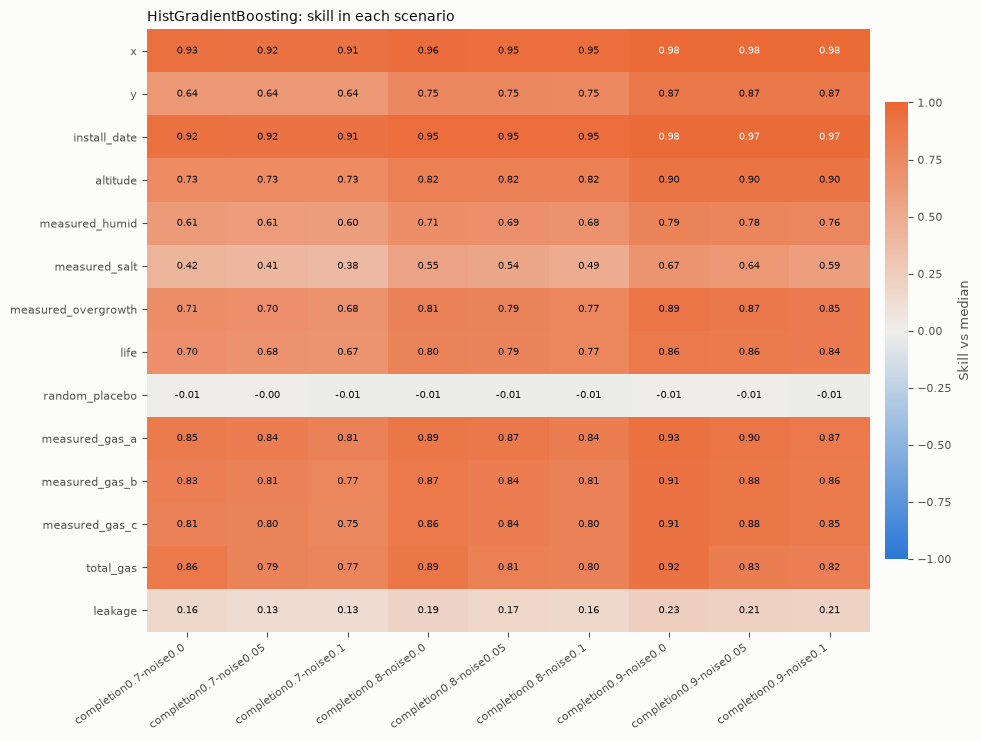

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
HistGradientBoosting,0.9697,0.9683,0.9434,0.9873,0.9802,0.9659,0.999,0.997,0.9829


,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,HistGradientBoosting,675,580.995,5.594,0.869


Tasks: 900 | failed: 0 | with warnings: 0


In [14]:
STUDY.run_model("HistGradientBoosting")
STUDY.show_model("HistGradientBoosting")


### 4.6 CatBoost

CatBoost is gradient boosting on symmetric trees, where every node at a given depth uses the same split. This acts as built-in regularisation, and its training order reduces overfitting on small data.

**Setup:** no scaling, and gaps are handled natively. `model_id` enters as one-hot columns, the same as for other models, so the comparison does not depend on category handling. Tuning chooses the depth, the learning rate, the number of rounds and leaf regularisation.

**What to look for:** whether its stronger regularisation gives a better result than HistGradientBoosting on noisy targets.

Tuning: 195 candidates
19/195 tasks, 24 s
38/195 tasks, 56 s
57/195 tasks, 79 s
76/195 tasks, 110 s
95/195 tasks, 132 s
114/195 tasks, 160 s
133/195 tasks, 186 s
152/195 tasks, 208 s
171/195 tasks, 237 s
190/195 tasks, 300 s
195/195 tasks, 464 s
Experiments: 1695 tasks
169/1695 tasks, 90 s
338/1695 tasks, 180 s
507/1695 tasks, 271 s
676/1695 tasks, 362 s
845/1695 tasks, 453 s
1014/1695 tasks, 507 s
1183/1695 tasks, 582 s
1352/1695 tasks, 657 s
1521/1695 tasks, 735 s
1690/1695 tasks, 811 s
1695/1695 tasks, 817 s


**Tuning** (cross-validated loss on observed labels)

,method,targets,targets changed,largest loss reduction
0,CatBoost,15,15,-0.2655


,target,method,settings
0,x,CatBoost,"{""depth"": 6, ""iterations"": 1000, ""l2_leaf_reg"": 1, ""learning_rate"": 0.05}"
1,y,CatBoost,"{""depth"": 6, ""iterations"": 1000, ""l2_leaf_reg"": 1, ""learning_rate"": 0.05}"
2,install_date,CatBoost,"{""depth"": 6, ""iterations"": 1000, ""l2_leaf_reg"": 1, ""learning_rate"": 0.05}"
3,altitude,CatBoost,"{""depth"": 6, ""iterations"": 1000, ""l2_leaf_reg"": 1, ""learning_rate"": 0.05}"
4,measured_humid,CatBoost,"{""depth"": 6, ""iterations"": 1000, ""l2_leaf_reg"": 1, ""learning_rate"": 0.05}"
5,measured_salt,CatBoost,"{""depth"": 6, ""iterations"": 1000, ""l2_leaf_reg"": 1, ""learning_rate"": 0.05}"
6,measured_overgrowth,CatBoost,"{""depth"": 8, ""iterations"": 1000, ""l2_leaf_reg"": 3, ""learning_rate"": 0.05}"
7,life,CatBoost,"{""depth"": 8, ""iterations"": 1000, ""l2_leaf_reg"": 3, ""learning_rate"": 0.05}"
8,random_placebo,CatBoost,"{""depth"": 6, ""iterations"": 250, ""l2_leaf_reg"": 3, ""learning_rate"": 0.03}"
9,measured_gas_a,CatBoost,"{""depth"": 8, ""iterations"": 250, ""l2_leaf_reg"": 3, ""learning_rate"": 0.05}"


**CatBoost · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact,tuning change
0,x,1.4854,3.2748,0.9870,0.1508,0.9403,0.7824,0.9246,0.4352,-0.2811
1,y,6.4591,12.7399,0.8077,-0.4803,0.7449,0.3773,0.7596,0.1364,-0.1036
2,install_date,21.4668,46.0594,0.9866,1.4090,0.9375,0.4790,0.8368,0.0385,-0.2538
3,altitude,5.8339,12.3360,0.9105,-0.2596,0.8278,0.4590,0.7902,0.1815,-0.1110
4,measured_humid,0.0528,0.0795,0.8533,0.0021,0.6948,0.4919,0.5766,NaN,-0.0640
5,measured_salt,0.1002,0.1450,0.6560,0.0015,0.5266,0.3600,0.4721,NaN,-0.0696
6,measured_overgrowth,0.0615,0.1140,0.9026,0.0039,0.7954,0.5356,0.6421,NaN,-0.1029
7,life,59.6098,103.4146,0.9278,-1.1455,0.7945,0.8417,0.9913,NaN,-0.2608
8,random_placebo,0.2554,0.2933,-0.0176,0.0136,-0.0092,0.0975,0.1457,NaN,-0.0028
9,measured_gas_a,170.9783,286.6775,0.9590,2.2839,0.8630,0.9579,0.9809,NaN,-0.0039


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
8,CatBoost,1965,0.9796,0.9785,0.9786


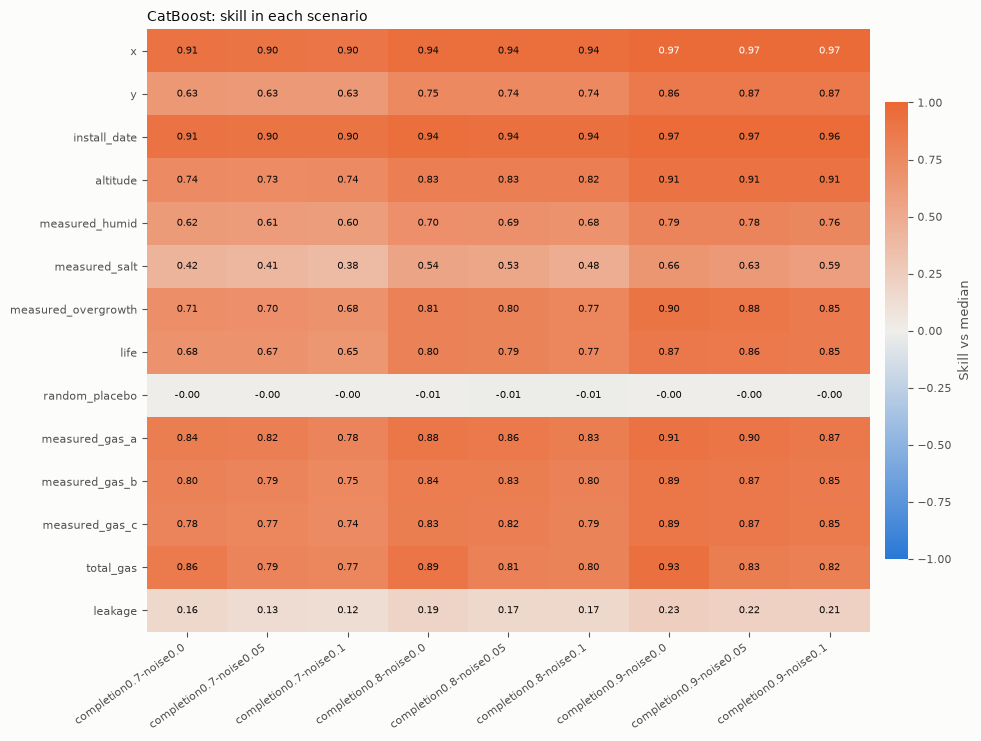

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
CatBoost,0.969,0.965,0.9356,0.9832,0.9796,0.9634,0.999,0.999,0.9849


,method,tasks,fit seconds,predict seconds,seconds per target and fold
1,CatBoost,675,4313.893,2.483,6.395


Tasks: 1695 | failed: 0 | with warnings: 0


In [15]:
STUDY.run_model("CatBoost")
STUDY.show_model("CatBoost")


### 4.7 miceforest direct

miceforest uses LightGBM, another gradient boosting library. Here it runs as a direct single-target prediction, without donor matching, so it is comparable with the other single-target models. The project's audited compatibility patch for miceforest 6.0.5 is used throughout.

**Setup:** no scaling, and gaps are handled natively. Tuning chooses the number of rounds, the leaf count, the minimum leaf size and the learning rate.

**What to look for:** this is the reference for sections 4.8 and 4.9, which share this engine but add donor matching and joint imputation.

Tuning: 195 candidates
19/195 tasks, 12 s
38/195 tasks, 21 s
57/195 tasks, 32 s
76/195 tasks, 41 s
95/195 tasks, 51 s
114/195 tasks, 59 s
133/195 tasks, 68 s
152/195 tasks, 76 s
171/195 tasks, 85 s
190/195 tasks, 102 s
195/195 tasks, 110 s
Experiments: 900 tasks
90/900 tasks, 24 s
180/900 tasks, 49 s
270/900 tasks, 74 s
360/900 tasks, 100 s
450/900 tasks, 126 s
540/900 tasks, 153 s
630/900 tasks, 179 s
720/900 tasks, 205 s
810/900 tasks, 231 s
900/900 tasks, 242 s


**Tuning** (cross-validated loss on observed labels)

,method,targets,targets changed,largest loss reduction
0,miceforest direct,15,15,-0.1628


,target,method,settings
0,x,miceforest direct,"{""learning_rate"": 0.05, ""min_data_in_leaf"": 20, ""num_leaves"": 63, ""rounds"": 400}"
1,y,miceforest direct,"{""learning_rate"": 0.1, ""min_data_in_leaf"": 20, ""num_leaves"": 63, ""rounds"": 400}"
2,install_date,miceforest direct,"{""learning_rate"": 0.05, ""min_data_in_leaf"": 20, ""num_leaves"": 63, ""rounds"": 400}"
3,altitude,miceforest direct,"{""learning_rate"": 0.1, ""min_data_in_leaf"": 20, ""num_leaves"": 63, ""rounds"": 400}"
4,measured_humid,miceforest direct,"{""learning_rate"": 0.05, ""min_data_in_leaf"": 20, ""num_leaves"": 63, ""rounds"": 400}"
5,measured_salt,miceforest direct,"{""learning_rate"": 0.05, ""min_data_in_leaf"": 20, ""num_leaves"": 63, ""rounds"": 400}"
6,measured_overgrowth,miceforest direct,"{""learning_rate"": 0.03, ""min_data_in_leaf"": 20, ""num_leaves"": 63, ""rounds"": 100}"
7,life,miceforest direct,"{""learning_rate"": 0.03, ""min_data_in_leaf"": 20, ""num_leaves"": 63, ""rounds"": 200}"
8,random_placebo,miceforest direct,"{""learning_rate"": 0.1, ""min_data_in_leaf"": 20, ""num_leaves"": 15, ""rounds"": 100}"
9,measured_gas_a,miceforest direct,"{""learning_rate"": 0.03, ""min_data_in_leaf"": 10, ""num_leaves"": 31, ""rounds"": 200}"


**miceforest direct · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact,tuning change
0,x,1.9523,4.1638,0.9790,0.2146,0.9216,0.7045,0.9060,0.3719,-0.1862
1,y,8.4384,13.3245,0.7897,-0.3061,0.6667,0.1899,0.5434,0.0576,-0.1466
2,install_date,27.2980,58.6386,0.9782,0.4110,0.9205,0.4192,0.7861,0.0335,-0.1704
3,altitude,8.2193,13.5725,0.8916,0.1298,0.7574,0.2079,0.5853,0.0766,-0.1366
4,measured_humid,0.0641,0.0889,0.8166,0.0018,0.6297,0.3952,0.5025,NaN,-0.0940
5,measured_salt,0.1258,0.1618,0.5719,0.0019,0.4059,0.2252,0.3382,NaN,-0.0793
6,measured_overgrowth,0.0802,0.1253,0.8822,0.0018,0.7333,0.4337,0.5280,NaN,-0.1234
7,life,101.5079,147.2641,0.8536,-4.5940,0.6500,0.6420,0.9903,NaN,-0.1298
8,random_placebo,0.2539,0.2917,-0.0066,0.0129,-0.0034,0.1019,0.1437,NaN,0.0002
9,measured_gas_a,185.9588,307.4186,0.9528,-3.6525,0.8510,0.9403,0.9780,NaN,-0.0131


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
4,miceforest direct,1965,0.9822,0.9811,0.9817


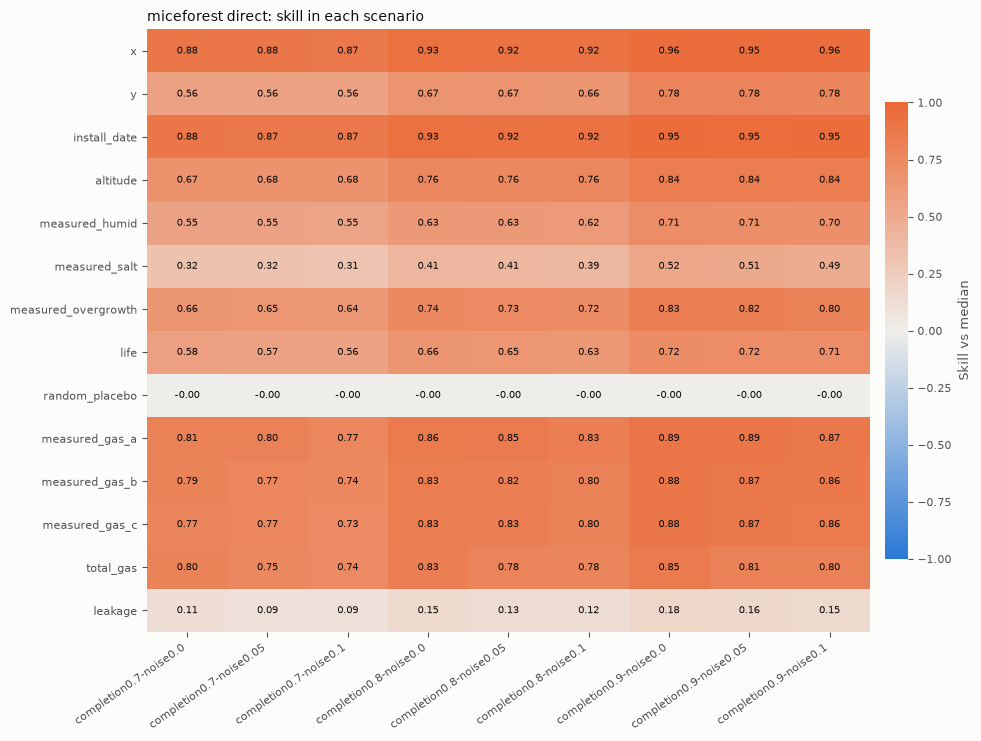

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
miceforest direct,0.966,0.9623,0.9333,0.9847,0.9822,0.9588,0.999,0.997,0.9769


,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,miceforest direct,675,2281.525,6.436,3.39


Tasks: 900 | failed: 0 | with warnings: 0


In [16]:
STUDY.run_model("miceforest direct")
STUDY.show_model("miceforest direct")


### 4.8 miceforest PMM

Predictive mean matching (PMM) does not use a model's prediction as the imputed value. It finds observed rows with similar predictions and copies a real value from one of them. Repeating this gives 20 completed datasets, so the imputed values keep a realistic spread and show their uncertainty.

**Setup:** the settings tuned in section 4.7, with five candidate donors per cell. It runs in the representative scenario for numeric targets. The results table scores the mean of the 20 draws.

**What to look for:** the mean of the draws is judged here on point error, but the purpose of PMM is the spread, which is assessed below and in section 7.1.

In [17]:
STUDY.run_model("miceforest PMM")
STUDY.show_model("miceforest PMM")


Experiments: 70 tasks
7/70 tasks, 51 s
14/70 tasks, 113 s
21/70 tasks, 147 s
28/70 tasks, 180 s
35/70 tasks, 228 s
42/70 tasks, 257 s
49/70 tasks, 302 s
56/70 tasks, 331 s
63/70 tasks, 377 s
70/70 tasks, 411 s


**miceforest PMM · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,2.2146,4.2063,0.9786,0.2146,0.9110,0.6231,0.9060,0.2714
1,y,8.2611,13.4749,0.7849,-0.2540,0.6737,0.1854,0.5778,0.0616
2,install_date,31.1850,59.7803,0.9774,0.0578,0.9092,0.2960,0.7339,0.0223
3,altitude,8.5505,13.6709,0.8901,0.0323,0.7476,0.1760,0.5460,0.0641
4,measured_humid,0.0655,0.0906,0.8096,0.0024,0.6214,0.3654,0.4798,NaN
5,measured_salt,0.1194,0.1614,0.5736,0.0026,0.4362,0.2475,0.3550,NaN
6,measured_overgrowth,0.0775,0.1259,0.8810,0.0027,0.7423,0.3885,0.4835,NaN
7,life,101.2946,147.5009,0.8531,-4.2070,0.6508,0.6389,0.9888,NaN
8,random_placebo,0.2652,0.3113,-0.1463,0.0188,-0.0479,0.1004,0.1566,NaN
9,measured_gas_a,184.2686,294.2659,0.9568,-3.0850,0.8523,0.9511,0.9804,NaN


,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,miceforest PMM,70,4404.49,158.306,65.183


Tasks: 70 | failed: 0 | with warnings: 70


**Spread of the draws.** A useful spread contains the truth about as often as it claims to, here 80% of the time for the band from the 10th to the 90th percentile. This spread is not a validated prediction interval.

In [18]:
display(ev.draw_table(STUDY.scored["miceforest PMM"], STUDY.draws["miceforest PMM"], STUDY.config).round(4))


,target,method,n,draws,distinct draws per cell,truth in 80% band,mean band width
0,random_placebo,miceforest PMM,2011,20,19.9070,0.6653,0.6721
1,measured_overgrowth,miceforest PMM,1959,20,13.5753,0.8030,0.2001
2,measured_gas_a,miceforest PMM,2043,20,17.7215,0.9232,808.8206
3,measured_gas_b,miceforest PMM,2039,20,17.8058,0.9294,822.7005
4,leakage,miceforest PMM,1948,20,19.5026,0.6930,0.2289
5,measured_gas_c,miceforest PMM,2049,20,17.9566,0.9092,773.2223
6,life,miceforest PMM,1958,20,18.5827,0.6864,246.9557
7,install_date,miceforest PMM,1973,20,13.3578,0.7187,70.6805
8,x,miceforest PMM,1990,20,6.3030,0.7894,4.9964
9,measured_salt,miceforest PMM,1972,20,19.0527,0.6998,0.3290


### 4.9 Joint miceforest PMM

The joint model imputes all incomplete columns together by chained equations: each column is modelled from all the others, repeatedly, with donor matching. Unlike the single-target models, it fills a row's hidden cells as one process, and it also covers `model_id`.

**Setup:** one shared setting, since a joint model has no per-target choice, so it keeps the earlier study's values and is not tuned. It produces 20 completed datasets in the representative scenario. The results table scores the mean of the draws, or the majority vote for `model_id`.

**What to look for:** whether imputing columns together keeps completed rows more consistent. Section 6.4 checks this.

In [19]:
STUDY.run_model("Joint miceforest PMM")
STUDY.show_model("Joint miceforest PMM")


Experiments: 5 tasks
1/5 tasks, 179 s
2/5 tasks, 180 s
3/5 tasks, 181 s
4/5 tasks, 181 s
5/5 tasks, 182 s


**Joint miceforest PMM · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,1.9472,4.9292,0.9706,0.2296,0.9218,0.7915,0.8874,0.5432
1,y,7.3737,13.1335,0.7956,0.2677,0.7088,0.2389,0.6742,0.0803
2,install_date,27.6954,68.5229,0.9703,2.0461,0.9193,0.5666,0.8251,0.0461
3,altitude,7.7832,13.3026,0.8959,0.3461,0.7702,0.1994,0.6350,0.0666
4,measured_humid,0.0657,0.0920,0.8036,0.0047,0.6204,0.3911,0.4980,NaN
5,measured_salt,0.1142,0.1559,0.6024,0.0016,0.4604,0.2850,0.3884,NaN
6,measured_overgrowth,0.0818,0.1300,0.8732,0.0040,0.7280,0.3862,0.5096,NaN
7,life,82.6686,124.8055,0.8949,-1.2584,0.7150,0.7191,0.9944,NaN
8,random_placebo,0.2667,0.3126,-0.1560,0.0118,-0.0541,0.0940,0.1432,NaN
9,measured_gas_a,171.9365,304.9047,0.9536,-19.8673,0.8622,0.9574,0.9780,NaN


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
0,Joint miceforest PMM,1965,0.9822,0.9812,0.9807


,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,Joint miceforest PMM,5,773.166,121.058,178.845


Tasks: 5 | failed: 0 | with warnings: 5


**Spread of the draws.** Read as in section 4.8.

In [20]:
display(ev.draw_table(STUDY.scored["Joint miceforest PMM"], STUDY.draws["Joint miceforest PMM"], STUDY.config).round(4))


,target,method,n,draws,distinct draws per cell,truth in 80% band,mean band width,truth among draws
0,x,Joint miceforest PMM,1990,20,6.1779,0.9322,6.2365,NaN
1,y,Joint miceforest PMM,1980,20,13.5460,0.8237,22.7816,NaN
2,install_date,Joint miceforest PMM,1973,20,13.9787,0.8505,86.3723,NaN
3,altitude,Joint miceforest PMM,2011,20,13.6594,0.8130,23.5000,NaN
4,measured_humid,Joint miceforest PMM,1984,20,19.4869,0.7641,0.1953,NaN
5,measured_salt,Joint miceforest PMM,1972,20,19.7627,0.7754,0.3572,NaN
6,measured_overgrowth,Joint miceforest PMM,1959,20,14.0781,0.8734,0.2543,NaN
7,life,Joint miceforest PMM,1958,20,19.2176,0.7707,239.5119,NaN
8,random_placebo,Joint miceforest PMM,2011,20,19.9388,0.6663,0.6659,NaN
9,measured_gas_a,Joint miceforest PMM,2043,20,19.0857,0.9623,836.6155,NaN


## 5. Comparing the models

All results below combine the model sections. Charts show the representative scenario.

,planned tasks,finished tasks,succeeded,failed,tasks with warnings
0,7875,7875,7875,0,87


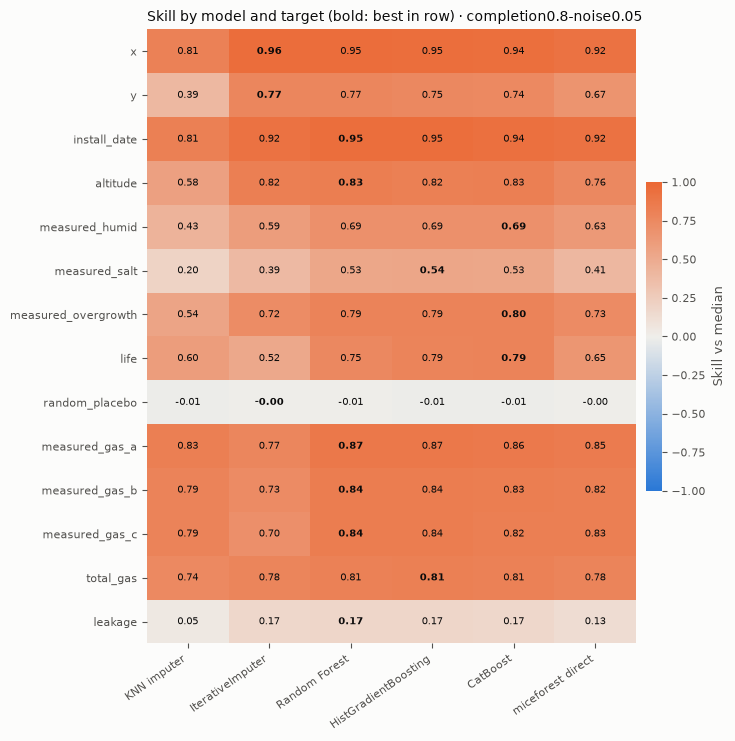

,method,n,accuracy,macro F1,balanced accuracy
0,Mode,1965,0.2809,0.1774,0.2483
1,KNN,1965,0.9740,0.9726,0.9730
2,Random Forest,1965,0.9771,0.9758,0.9753
3,HistGradientBoosting,1965,0.9802,0.9790,0.9787
4,CatBoost,1965,0.9796,0.9785,0.9786
5,miceforest direct,1965,0.9822,0.9811,0.9817


In [21]:
STUDY.finish()
NUMERIC, CATEGORY, PAIRS, GROUPS = STUDY.numeric, STUDY.category, STUDY.pairs, STUDY.groups
SCORED, DRAWS, FIGURES = STUDY.all_scored, STUDY.all_draws, STUDY.figures
display(ev.run_summary(STUDY.log, PLAN))

main_rep = NUMERIC[NUMERIC.experiment.eq("main") & NUMERIC.scenario.eq(REPRESENTATIVE) & NUMERIC.method.ne("Median")]
skill = main_rep.pivot(index="target", columns="method", values="skill").reindex(list(NUMERIC_TARGETS))
skill = skill[[m for m in NUMERIC_METHODS if m != "Median"]]
fg.plot_heatmap(skill, f"Skill by model and target (bold: best in row) · {REPRESENTATIVE}", FIGURES, "skill_by_model",
                "Skill vs median", center=0.0, limit=1.0, marks=skill.eq(skill.max(axis=1), axis=0).to_numpy())
labels = CATEGORY[CATEGORY.experiment.eq("main") & CATEGORY.scenario.eq(REPRESENTATIVE)]
display(labels.set_index("method").reindex(CATEGORY_METHODS).reset_index()[
    ["method", "n", "accuracy", "macro F1", "balanced accuracy"]].round(4))


**Are the differences clear?** The intervals resample rows for fitted models. They do not include refitting or the randomness of the dataset itself, so they show whether a gap is clear on these cells rather than proving it in general. A gap can be clear and still too small to matter, so the last column shows it relative to the better method's error.

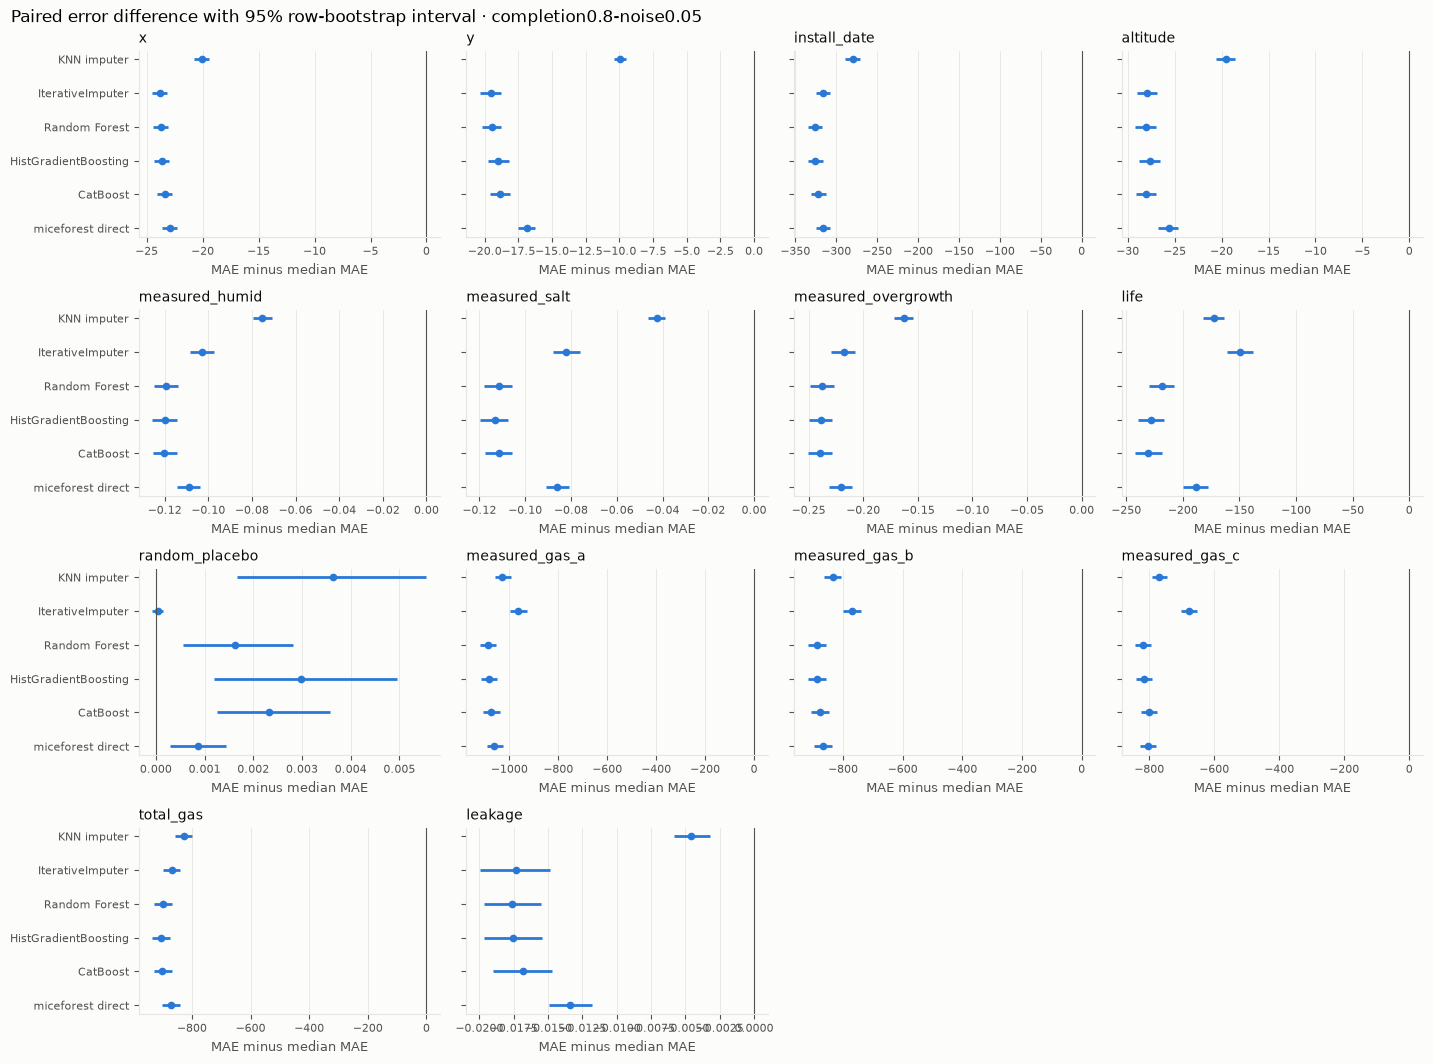

,target,first,second,metric,difference,low,high,relative gap
0,x,IterativeImputer,Random Forest,MAE,0.08593,-0.08500,0.26735,0.08116
1,y,IterativeImputer,Random Forest,MAE,0.01364,-0.30821,0.35864,0.00235
2,install_date,Random Forest,HistGradientBoosting,MAE,0.34313,-0.50691,1.12291,0.01999
3,altitude,Random Forest,CatBoost,MAE,0.01442,-0.18051,0.21037,0.00248
4,measured_humid,CatBoost,HistGradientBoosting,MAE,0.00019,-0.00112,0.00144,0.00368
5,measured_salt,HistGradientBoosting,Random Forest,MAE,0.00175,-0.00009,0.00369,0.01782
6,measured_overgrowth,CatBoost,HistGradientBoosting,MAE,0.00033,-0.00169,0.00243,0.00541
7,life,CatBoost,HistGradientBoosting,MAE,2.16303,0.08680,4.25509,0.03629
8,random_placebo,IterativeImputer,miceforest direct,MAE,0.00081,0.00027,0.00136,0.00321
9,measured_gas_a,Random Forest,HistGradientBoosting,MAE,3.23933,-1.28216,7.78557,0.02034


In [22]:
fg.plot_paired(PAIRS, REPRESENTATIVE, FIGURES)
closest = PAIRS[PAIRS.scenario.eq(REPRESENTATIVE) & PAIRS.comparison.eq("best two")].copy()
closest["relative gap"] = closest["second error"] / closest["first error"].where(closest["first error"] > 0) - 1
closest = closest.set_index("target").reindex(list(TARGETS)).reset_index()
display(closest[["target", "first", "second", "metric", "difference", "low", "high", "relative gap"]].round(5))


**What tuning changed.** The chart shows the change in MAE, or the error rate for `model_id`, on the same hidden cells; negative values mean tuning helped.

**Predictions outside the valid range.** The table shows the share of raw predictions outside the range a column allows. A method can show low error and still produce impossible values. Scoring uses the limited values.

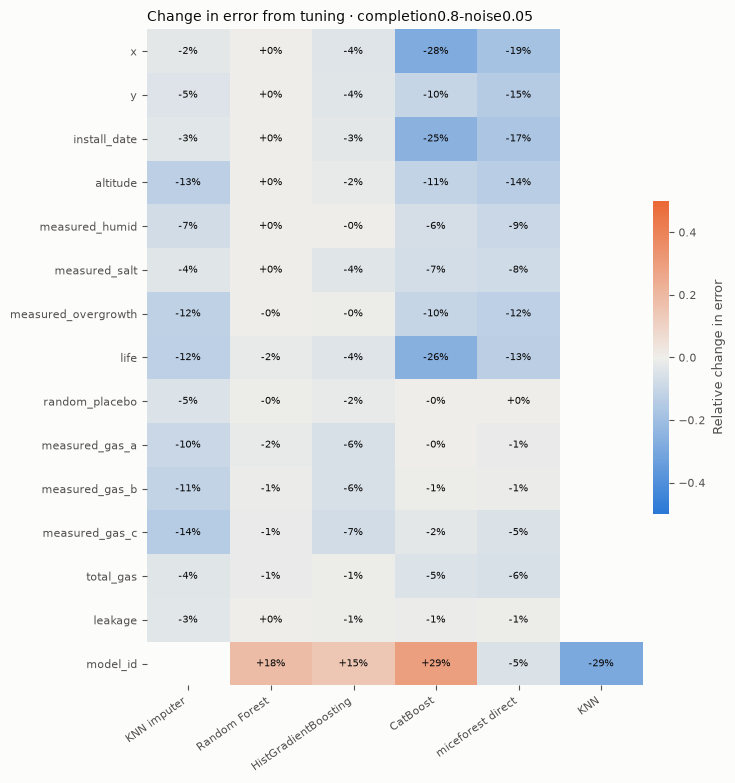

method,Median,KNN imputer,IterativeImputer,Random Forest,HistGradientBoosting,CatBoost,miceforest direct
target,,,,,,,
x,0.0,0.0,0.0082,0.0,0.0034,0.0047,0.0
y,0.0,0.0,0.0109,0.0,0.0013,0.0022,0.0
install_date,0.0,0.0,0.0042,0.0,0.0003,0.0021,0.0
altitude,0.0,0.0,0.0000,0.0,0.0000,0.0001,0.0
measured_humid,0.0,0.0,0.0106,0.0,0.0003,0.0023,0.0
measured_salt,0.0,0.0,0.0307,0.0,0.0007,0.0030,0.0
measured_overgrowth,0.0,0.0,0.1562,0.0,0.0985,0.1267,0.0
life,0.0,0.0,0.0000,0.0,0.0000,0.0000,0.0
random_placebo,0.0,0.0,0.0089,0.0,0.0000,0.0000,0.0


In [23]:
comparison = ev.default_comparison(NUMERIC, CATEGORY, STUDY.config)
methods = [m for m in dict.fromkeys(NUMERIC_METHODS + CATEGORY_METHODS) if m in set(comparison.method)]
matrix = comparison.pivot(index="target", columns="method", values="relative change").reindex(list(TARGETS))[methods]
fg.plot_heatmap(matrix, f"Change in error from tuning · {REPRESENTATIVE}", FIGURES, "tuning_effect",
                "Relative change in error", center=0.0, limit=0.5, fmt="{:+.0%}")
ranges = ev.range_table(SCORED).pivot(index="target", columns="method", values="outside valid range")
display(ranges.reindex(list(NUMERIC_TARGETS))[list(NUMERIC_METHODS)].round(4))


## 6. Relationships and failure

Models were given no relationships, so anything they use was learned from the data. The generator's definitions are used here only to check the result.

### 6.1 Negative control

`random_placebo` is unrelated to every other column. A clear gain over the median would mean a method is finding structure that does not exist. Falling behind the median is a different problem: the method is fitting noise. The last table is the same control from the other side: importance given to `random_placebo` as a predictor should stay near zero.

In [24]:
control = NUMERIC[NUMERIC.experiment.eq("main") & NUMERIC.target.eq("random_placebo")]
display(control.pivot(index="method", columns="scenario", values="skill").reindex(NUMERIC_METHODS).round(4))
comparisons = PAIRS[PAIRS.target.eq("random_placebo") & PAIRS.comparison.eq("versus baseline")]
print("Scenarios where each method is clearly better or worse than the median:")
display(comparisons.assign(better=comparisons.high.lt(0), worse=comparisons.low.gt(0)).groupby("second")[["better", "worse"]].sum())
importance = STUDY.all_importance
placebo_use = importance[importance.predictor.eq("random_placebo") & importance.target.ne("random_placebo")]
display(placebo_use.groupby(["method", "scenario"]).importance.agg(["mean", "max"]).round(4))


scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
Median,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
KNN imputer,-0.0075,-0.0086,-0.0075,-0.0124,-0.0144,-0.0144,-0.0099,-0.0099,-0.0095
IterativeImputer,-0.0577,-0.0539,-0.1175,-0.0001,-0.0002,-0.0003,-0.0001,0.0000,-0.0001
Random Forest,-0.0035,-0.0031,-0.0033,-0.0082,-0.0064,-0.0055,0.0009,0.0008,-0.0018
HistGradientBoosting,-0.0075,-0.0033,-0.0108,-0.0131,-0.0118,-0.0123,-0.0056,-0.0072,-0.0081
CatBoost,-0.0034,-0.0021,-0.0009,-0.0071,-0.0092,-0.0086,-0.0040,-0.0018,-0.0028
miceforest direct,-0.0010,-0.0006,-0.0007,-0.0024,-0.0034,-0.0030,-0.0017,-0.0010,-0.0024


Scenarios where each method is clearly better or worse than the median:


,better,worse
second,,
CatBoost,0,3
HistGradientBoosting,0,5
IterativeImputer,0,3
KNN imputer,0,6
Random Forest,0,3
miceforest direct,0,3


mean     max
method        scenario                               
CatBoost      completion0.8-noise0.0  -0.0005  0.0010
              completion0.8-noise0.05 -0.0002  0.0034
              completion0.8-noise0.1   0.0004  0.0026
Random Forest completion0.8-noise0.0  -0.0004  0.0019
              completion0.8-noise0.05  0.0001  0.0033
              completion0.8-noise0.1  -0.0002  0.0022

### 6.2 Which columns did the models rely on?

Each predictor is shuffled in held-out rows, and the added error is measured against observed labels, so truth is not involved. A value of 1 means the shuffle cost as much as replacing the model with a constant guess. Bold values mark links in the generator's definition.

Importance is shared between columns that carry the same information, so a low value on a linked column does not prove the model missed it: another column may be supplying the same signal. Values come from one fold.

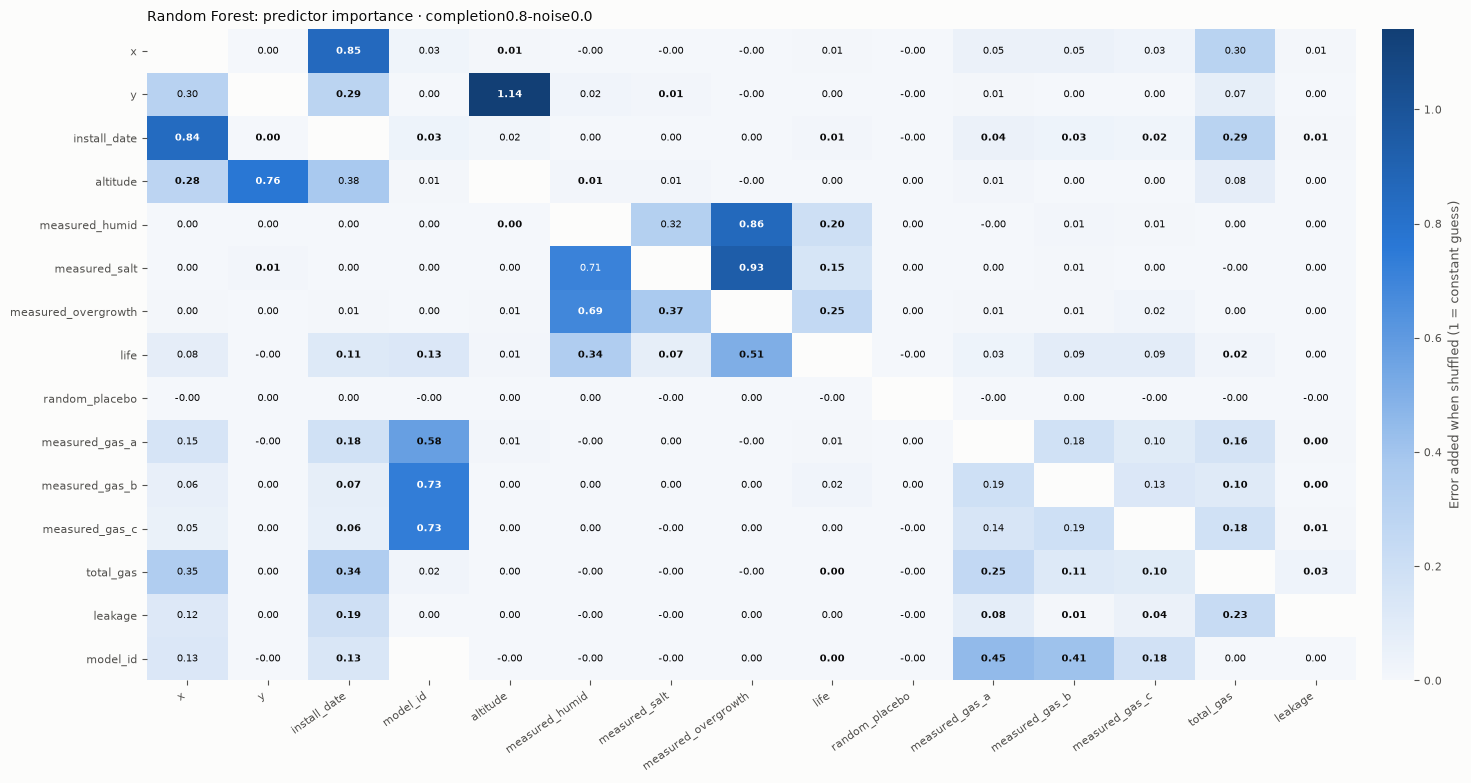

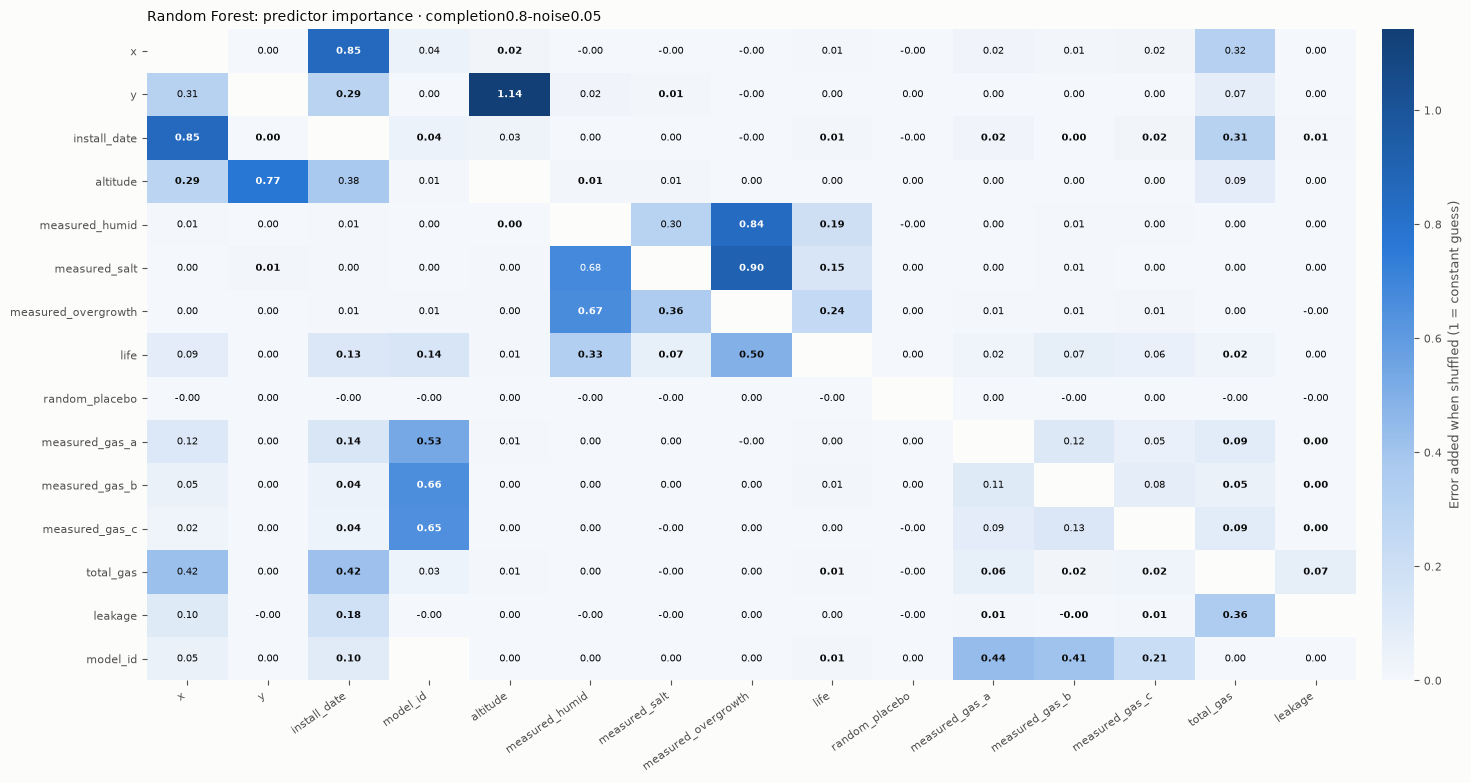

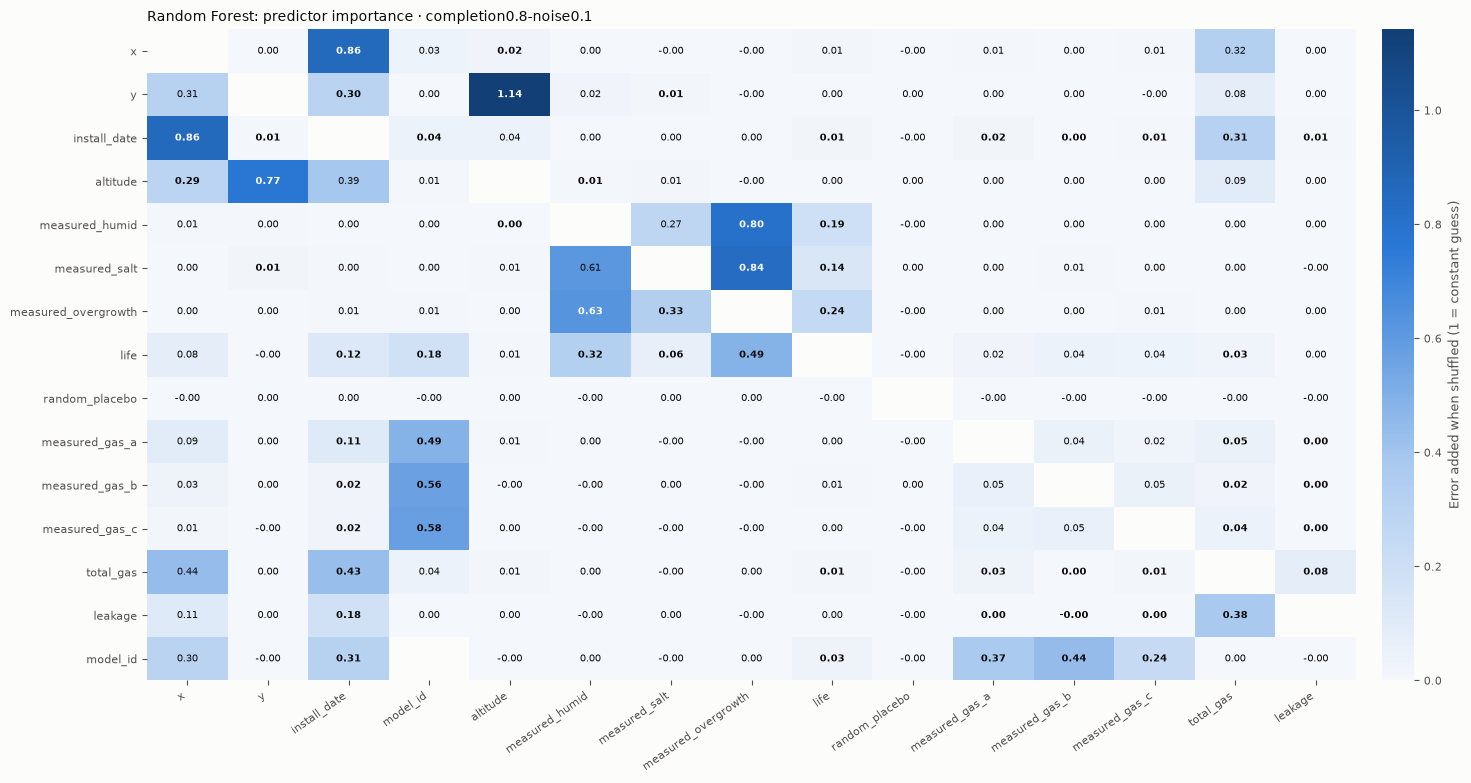

In [25]:
for scenario in (NOISE_FREE, REPRESENTATIVE, HIGH_NOISE):
    matrix = ev.importance_matrix(importance, scenario, "Random Forest")
    fg.plot_importance(matrix, f"Random Forest: predictor importance · {scenario}", FIGURES, f"importance_{scenario}")


### 6.3 Does accuracy depend on seeing the related columns?

Hidden cells are grouped by which related columns were visible in the same row, using measured data only. If a model has learned a relationship, skill should drop when the columns it depends on are hidden too.

Method shown below, the highest mean skill across targets: HistGradientBoosting


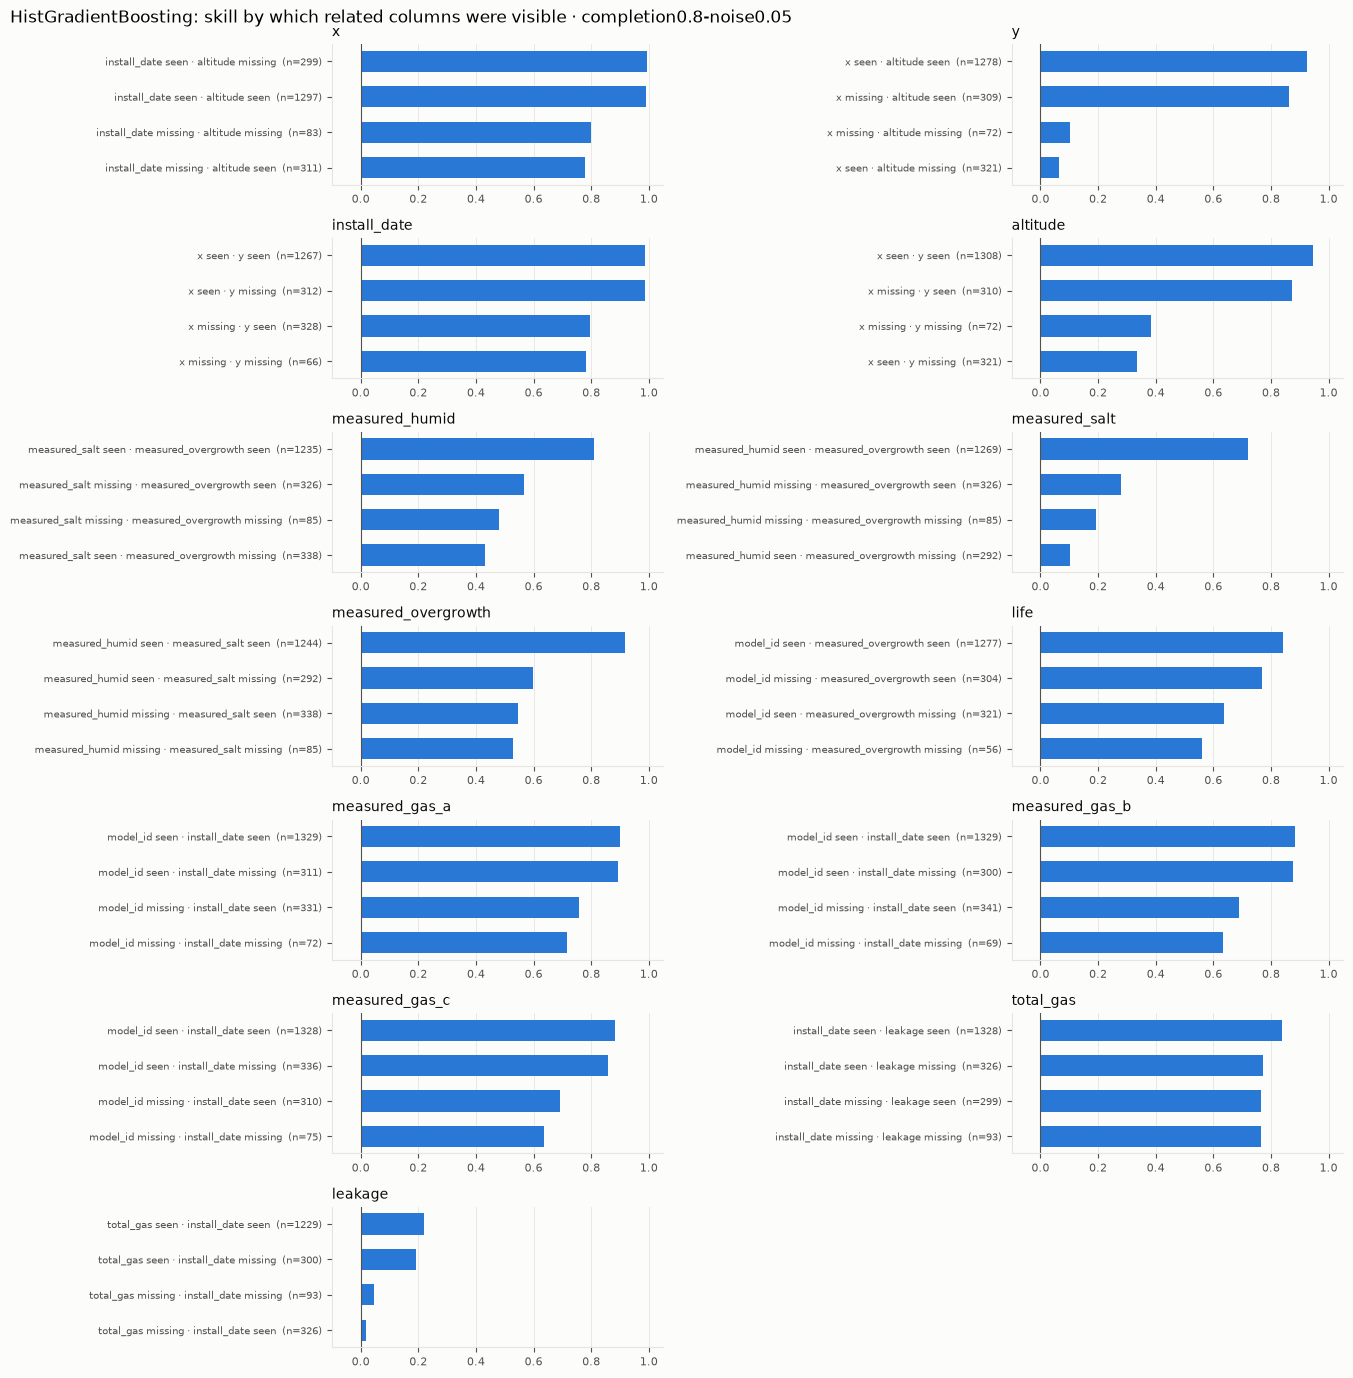

method                                                                         CatBoost  HistGradientBoosting  IterativeImputer    KNN  KNN imputer  Random Forest  miceforest direct
target              group                                                n                                                                                                           
altitude            x missing · y missing                                72       0.350                 0.385             0.230    NaN        0.349          0.397              0.324
                    x missing · y seen                                   310      0.902                 0.873             0.891    NaN        0.638          0.893              0.797
                    x seen · y missing                                   321      0.349                 0.335             0.178    NaN        0.308          0.332              0.297
                    x seen · y seen                                      1308     0.954                 0.945             1.000    NaN        0.641          0.958              0.885
install_date        x missing · y missing                                66       0.730                 0.780             0.463    NaN        0.671          0.781              0.695
                    x missing · y seen                                   328      0.795                 0.795             0.771    NaN        0.741          0.773              0.733
                    x seen · y missing                                   312      0.970                 0.985             0.919    NaN        0.824          0.990              0.966
                    x seen · y seen                                      1267     0.976                 0.988             0.982    NaN        0.838          0.993              0.968
leakage             total_gas missing · install_date missing             93       0.031                 0.047             0.034    NaN       -0.020          0.038              0.027
                    total_gas missing · install_date seen                326      0.049                 0.019             0.062    NaN       -0.013          0.038              0.031
                    total_gas seen · install_date missing                300      0.198                 0.191             0.202    NaN        0.056          0.198              0.137
                    total_gas seen · install_date seen                   1229     0.200                 0.221             0.204    NaN        0.063          0.216              0.167
life                model_id missing · measured_overgrowth missing       56       0.558                 0.561             0.244    NaN        0.358          0.543              0.467
                    model_id missing · measured_overgrowth seen          304      0.772                 0.769             0.464    NaN        0.586          0.728              0.615
                    model_id seen · measured_overgrowth missing          321      0.640                 0.636             0.424    NaN        0.387          0.600              0.510
                    model_id seen · measured_overgrowth seen             1277     0.851                 0.841             0.564    NaN        0.663          0.811              0.703
measured_gas_a      model_id missing · install_date missing              72       0.646                 0.714             0.606    NaN        0.507          0.733              0.628
                    model_id missing · install_date seen                 331      0.739                 0.757             0.614    NaN        0.610          0.762              0.703
                    model_id seen · install_date missing                 311      0.887                 0.894             0.809    NaN        0.878          0.898              0.881
                    model_id seen · install_date seen                    1329     0.901                 0.901             0.814    NaN        0.887          0.902              0.

In [26]:
best_overall = main_rep[main_rep.target.ne("random_placebo")].groupby("method").skill.mean().idxmax()
print("Method shown below, the highest mean skill across targets:", best_overall)
fg.plot_groups(GROUPS, REPRESENTATIVE, best_overall, FIGURES)
wide = GROUPS[GROUPS.scenario.eq(REPRESENTATIVE) & GROUPS.target.ne("random_placebo")
              & ~GROUPS.method.isin(["Median", "Mode"])]
display(wide.pivot_table(index=["target", "group", "n"], columns="method", values="skill").round(3))


### 6.4 Do completed rows stay consistent?

Three generator definitions can be checked directly on completed rows. Single-target methods fill each cell on its own, so a row can contradict itself even when each cell is close to the truth. The last column gives the same residual on rows with nothing imputed, which is the level measurement noise alone produces. A single joint draw is noisier than a point prediction by design, so the mean of the draws is shown beside it.

In [27]:
display(ev.coherence_table(SCORED, DRAWS, STUDY.measured[REPRESENTATIVE], STUDY.config).round(4))


,relation,method,rows,mean residual,residual in fully observed rows
0,altitude = x + y + 100,Median,4897,27.4631,0.0000
1,altitude = x + y + 100,KNN imputer,4897,9.8064,0.0000
2,altitude = x + y + 100,IterativeImputer,4897,0.0302,0.0000
3,altitude = x + y + 100,Random Forest,4897,1.9978,0.0000
4,altitude = x + y + 100,HistGradientBoosting,4897,2.5691,0.0000
5,altitude = x + y + 100,CatBoost,4897,2.4666,0.0000
6,altitude = x + y + 100,miceforest direct,4897,3.9665,0.0000
7,altitude = x + y + 100,Joint miceforest PMM (mean of draws),4897,3.4537,0.0000
8,altitude = x + y + 100,Joint miceforest PMM (one draw),4897,6.8716,0.0000
9,"overgrowth = max(2 humid - salt, 0)",Median,4789,0.2362,0.0174


### 6.5 Noise and completeness

The heatmap shows the best skill reached in each scenario. The two effect charts then measure each control on identical cells, so nothing else differs between the two sides. For completeness, the cells are those hidden at both levels: only the visible information around them has changed. Bold values have a 95% row-bootstrap interval that excludes zero.

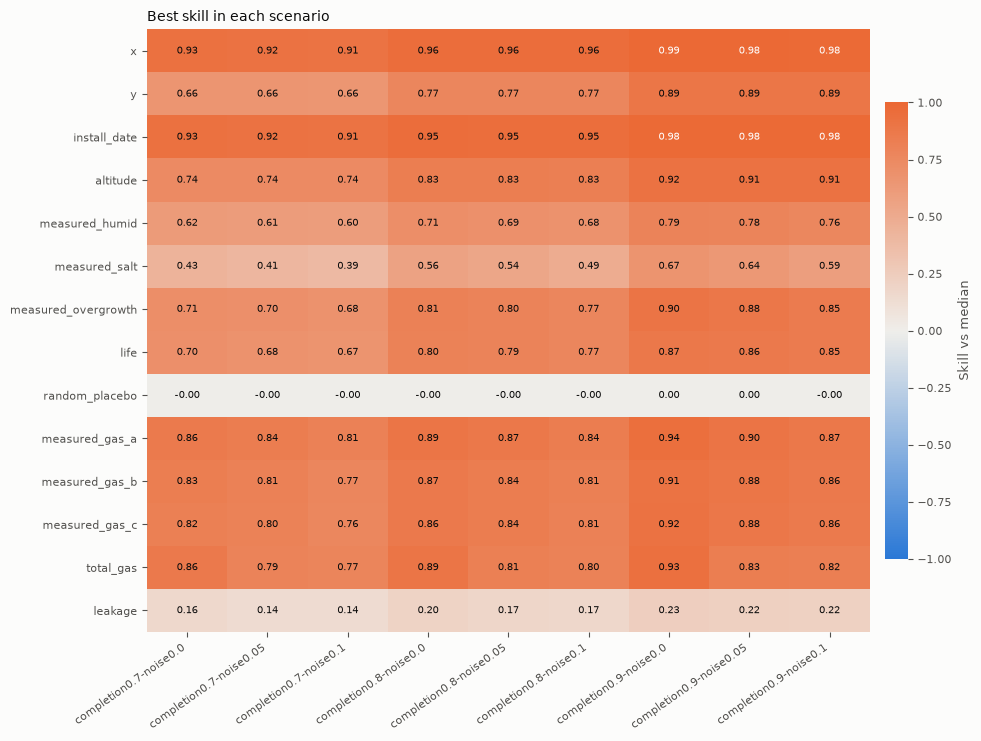

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
best model_id accuracy,0.971,0.9683,0.9434,0.9873,0.9822,0.9659,0.999,0.999,0.9849


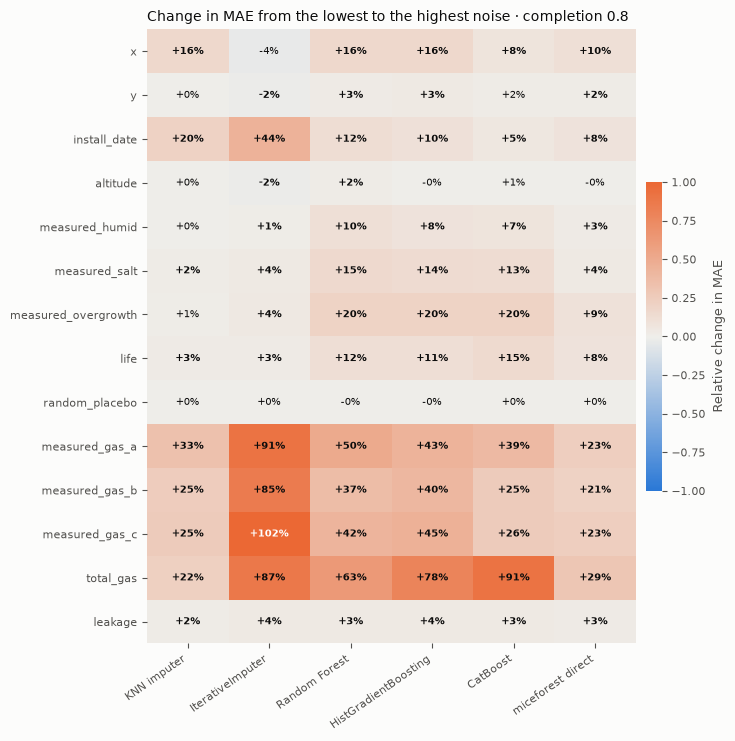

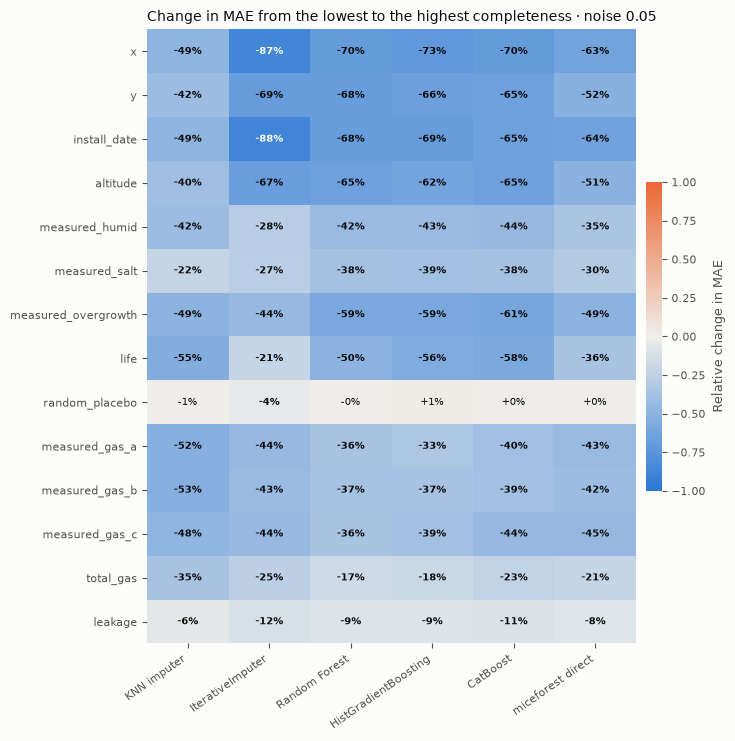

In [28]:
best_skill = NUMERIC[NUMERIC.experiment.eq("main") & NUMERIC.method.ne("Median")].groupby(
    ["target", "scenario"]).skill.max().unstack().reindex(list(NUMERIC_TARGETS))
fg.plot_heatmap(best_skill, "Best skill in each scenario", FIGURES, "best_skill_by_scenario", "Skill vs median",
                center=0.0, limit=1.0)
accuracy = CATEGORY[CATEGORY.experiment.eq("main") & CATEGORY.method.ne("Mode")].groupby("scenario").accuracy.max()
display(accuracy.rename("best model_id accuracy").to_frame().T.round(4))

completion_level, noise_level = 0.8, 0.05
noise_matrix, noise_marks = ev.effect_matrix(STUDY.effects, "noise", "held completion", completion_level)
fg.plot_heatmap(noise_matrix, f"Change in MAE from the lowest to the highest noise · completion {completion_level}",
                FIGURES, "noise_effect", "Relative change in MAE", center=0.0, limit=1.0, marks=noise_marks, fmt="{:+.0%}")
complete_matrix, complete_marks = ev.effect_matrix(STUDY.effects, "completeness", "held noise", noise_level)
fg.plot_heatmap(complete_matrix, f"Change in MAE from the lowest to the highest completeness · noise {noise_level}",
                FIGURES, "completeness_effect", "Relative change in MAE", center=0.0, limit=1.0, marks=complete_marks,
                fmt="{:+.0%}")


### 6.6 Removing predictor blocks

Each block is removed by what it measures, and the models are refitted. Values show the relative change in MAE: positive means the block was helping. Empty cells are targets inside the removed block.

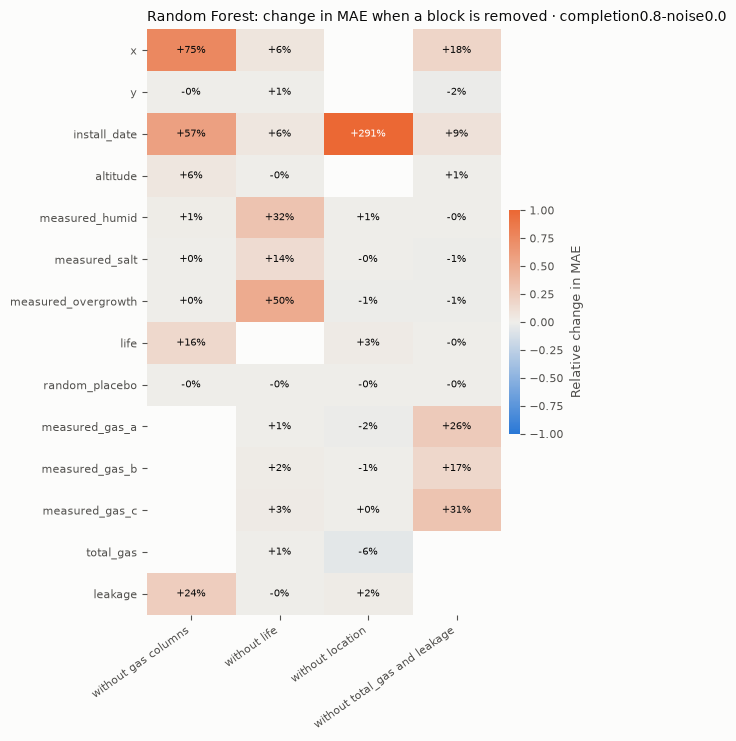

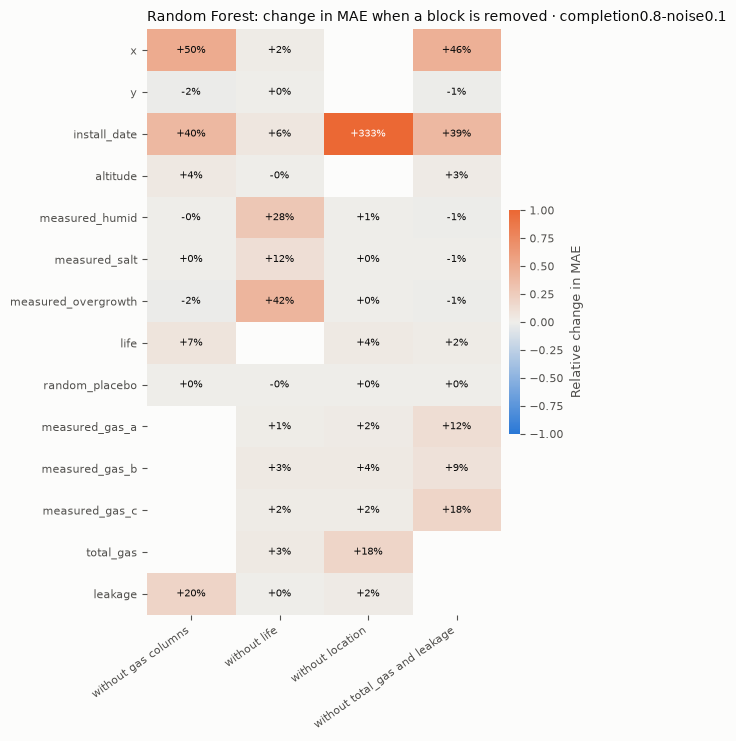

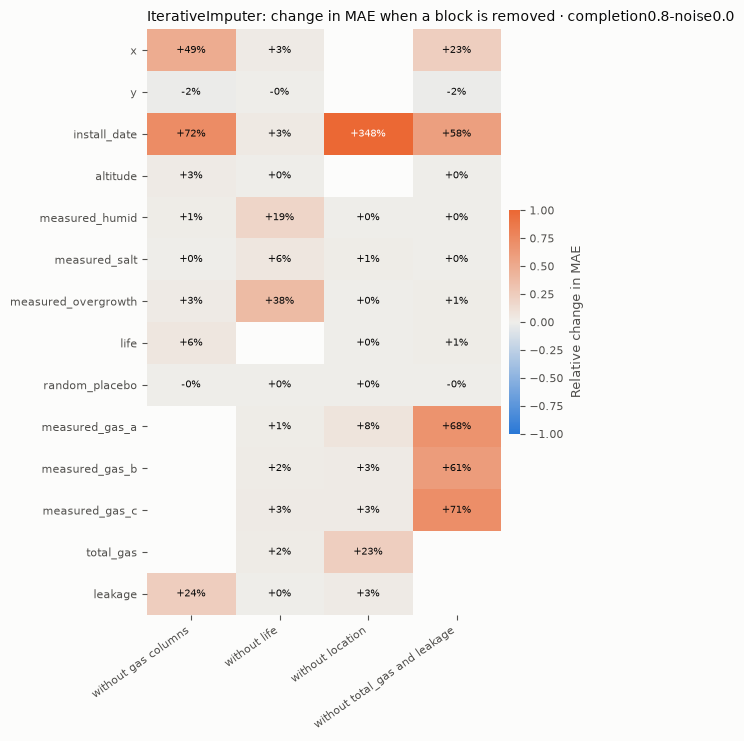

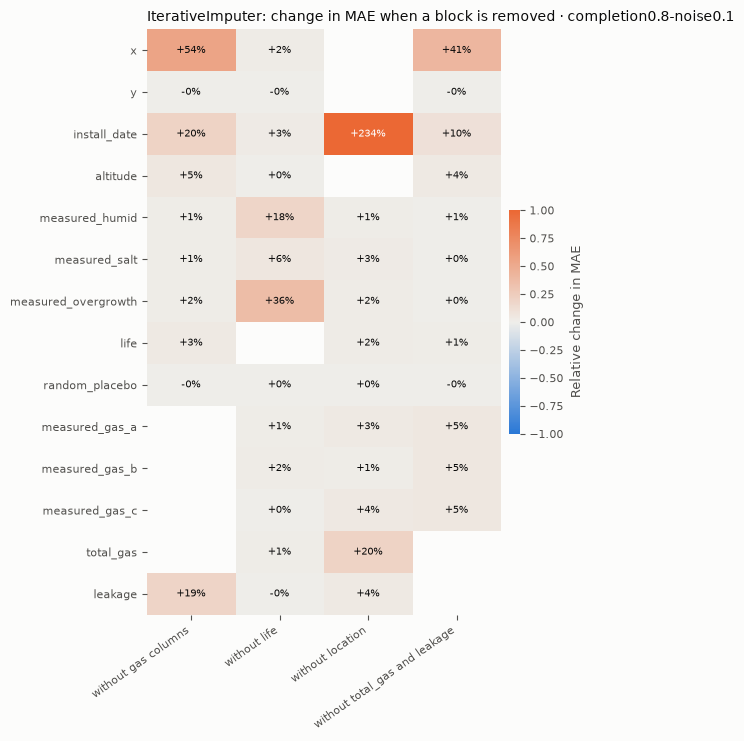

model_id accuracy without each block:


variant                                without gas columns  without life  without location  without total_gas and leakage
scenario                method                                                                                           
completion0.8-noise0.0  CatBoost                    0.7700        0.9796            0.9832                         0.9868
                        KNN                         0.6443        0.9746            0.9812                         0.9847
                        Random Forest               0.7786        0.9827            0.9832                         0.9847
completion0.8-noise0.05 CatBoost                    0.7654        0.9776            0.9822                         0.9817
                        KNN                         0.6483        0.9664            0.9756                         0.9791
                        Random Forest               0.7725        0.9796            0.9796                         0.9791
completion0.8-noise0.1  CatBoost                    0.7679        0.9532            0.9628                         0.9603
                        KNN                         0.6575        0.9191            0.9267                         0.9440
                        Random Forest               0.7771        0.9573            0.9603                         0.9613

In [29]:
for method in ("Random Forest", "IterativeImputer"):
    for scenario in (NOISE_FREE, HIGH_NOISE):
        block = STUDY.ablation[STUDY.ablation.method.eq(method) & STUDY.ablation.scenario.eq(scenario)]
        matrix = block.pivot(index="target", columns="variant", values="relative change").reindex(list(NUMERIC_TARGETS))
        slug = method.replace(" ", "_")
        fg.plot_heatmap(matrix, f"{method}: change in MAE when a block is removed · {scenario}", FIGURES,
                        f"ablation_{slug}_{scenario}", "Relative change in MAE", center=0.0, limit=1.0, fmt="{:+.0%}")
print("model_id accuracy without each block:")
display(STUDY.ablation_labels.pivot_table(index=["scenario", "method"], columns="variant", values="without").round(4))


### 6.7 Where in the value range errors concentrate

Cells are grouped by their true value after the fact, so this explains errors and cannot be used as a rule when filling data. Models that pull predictions towards the centre show large errors and opposite biases in the outer bands. `measured_overgrowth` is split into true zeros and positive values.

In [30]:
tails = ev.tail_table(SCORED, STUDY.config)
display(tails.pivot_table(index=["target", "band"], columns="method", values="MAE", sort=False)[list(NUMERIC_METHODS)].round(4))


method                                       Median  KNN imputer  IterativeImputer  Random Forest  HistGradientBoosting  CatBoost  miceforest direct
target              band                                                                                                                            
x                   lowest 10%              44.7391       4.1787            2.1111         0.6473                0.5990    1.2174             1.5749
                    middle 80%              19.7342       4.9487            0.8975         1.2532                1.3709    1.5778             2.0013
                    highest 10%             44.7635       4.1626            1.2414         0.8079                0.7488    1.0394             1.9557
y                   lowest 10%              44.7537      27.7635            9.0197         9.0985                9.5074   10.1921            14.5862
                    middle 80%              20.1759      11.9069            4.8706         4.8936                5.4296    5.5271             6.7380
                    highest 10%             45.1442      29.2404            9.7981         9.6779                9.8990    9.8462            15.2644
install_date        lowest 10%             615.5750      51.5700           49.7750        13.2800               11.7200   20.6850            28.7300
                    middle 80%             273.2308      65.4469           23.0871        18.2104               19.1151   22.5391            26.6491
                    highest 10%            622.4350      61.5750           38.8250        12.7900               10.6200   13.8150            30.9700
altitude            lowest 10%              70.8066      19.8585           11.1132         7.5849                8.1745    7.9009            11.7075
                    middle 80%              24.3715      12.4048            4.4896         5.1879                5.5833    5.2640             7.1446
                    highest 10%             68.9135      23.4183           11.8606         8.8510                9.0817    8.0865            12.8846
measured_humid      lowest 10%               0.2848       0.1575            0.1183         0.0868                0.0834    0.0872             0.1040
                    middle 80%               0.1307       0.0806            0.0639         0.0486                0.0489    0.0481             0.0566
                    highest 10%              0.3986       0.1755            0.0724         0.0603                0.0552    0.0559             0.0840
measured_salt       lowest 10%               0.3659       0.3134            0.1713         0.1356                0.1376    0.1402             0.2064
                    middle 80%               0.1653       0.1349            0.1141         0.0866                0.0858    0.0862             0.1033
                    highest 10%              0.4271       0.3003            0.2116         0.1716                0.1588    0.1722             0.2242
measured_overgrowth true zero                0.2279       0.1285            0.0577         0.0404                0.0373    0.0407             0.0600
                    positive, lower half     0.1152       0.0858            0.0911         0.0631                0.0667    0.0656             0.0768
                    positive, upper half     0.5598       0.2010            0.0995         0.0864                0.0817    0.0784             0.1040
life                lowest 10%             903.0371     319.5028          204.6297       148.8138              116.5416  111.0662           194.9112
                    middle 80%             192.7485      84.2099          125.3905        62.8331               54.9596   52.5694            89.9650
                    highest 10%            454.4207     179.5907          195.1419        60.6041               61.4406   64.4053           100.3304
random_placebo      lowest 10%               0.4536       0.4546            0.4530         0.4538                0.4546    0.4

## 7. Reliability

### 7.1 Do imputed values keep the shape of the data?

Accurate point predictions are usually smoother than real values, so a method can win on error and still narrow a column. PMM and the joint model are judged one completed dataset at a time, because averaging their draws first would remove the spread they exist to keep.

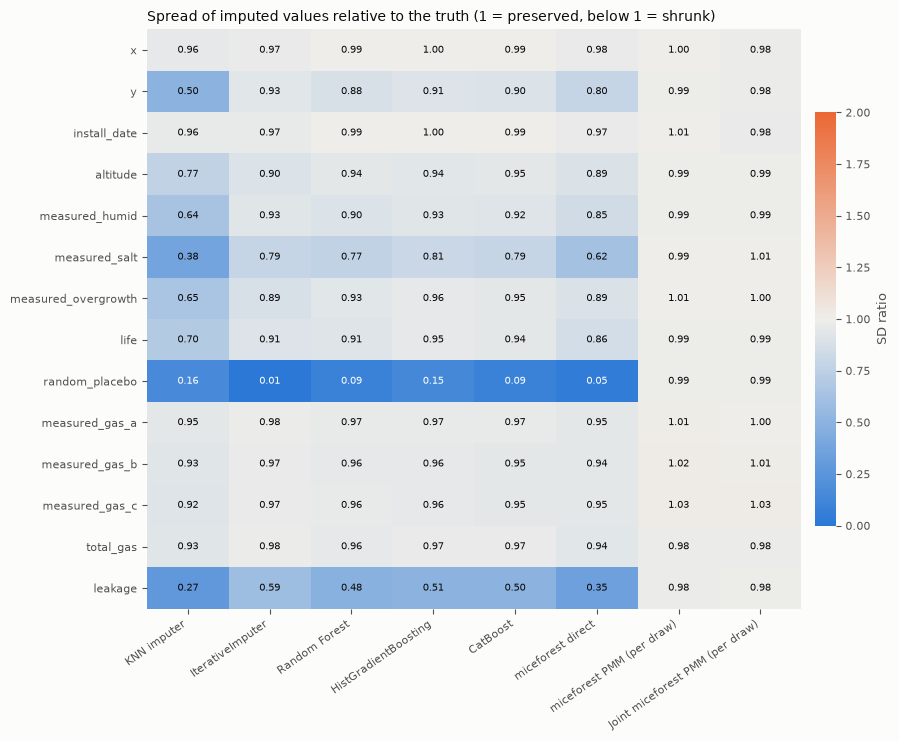

method,CatBoost,HistGradientBoosting,IterativeImputer,Joint miceforest PMM (per draw),KNN imputer,Median,Random Forest,miceforest PMM (per draw),miceforest direct
target,,,,,,,,,
x,0.2714,0.2754,0.8095,0.7043,1.2407,24.6844,0.2995,0.3297,0.7090
y,3.0894,2.9444,2.4258,0.8076,13.1242,24.8995,4.0202,0.6418,6.1384
install_date,3.5367,3.1891,17.4131,9.7065,18.8267,340.3193,4.3056,4.7283,10.7344
altitude,1.6191,2.1089,4.5699,0.8439,7.0905,33.4948,2.0860,0.8869,3.4973
measured_humid,0.0158,0.0139,0.0291,0.0076,0.0664,0.1725,0.0186,0.0054,0.0281
measured_salt,0.0511,0.0459,0.0624,0.0057,0.1364,0.2103,0.0592,0.0075,0.0875
measured_overgrowth,0.0205,0.0161,0.0479,0.0084,0.1149,0.2982,0.0256,0.0077,0.0383
life,18.1385,16.6802,34.2839,8.0443,84.8197,288.3616,28.2397,9.2614,45.1612
random_placebo,0.2333,0.2201,0.2512,0.0139,0.2166,0.2522,0.2329,0.0195,0.2430


,method,total variation,share gap 0,share gap 1,share gap 2,share gap 3
0,Mode,0.4366,0.3165,-0.2270,-0.2097,0.1201
1,KNN,0.0036,-0.0025,0.0031,0.0005,-0.0010
2,Random Forest,0.0046,0.0010,-0.0025,-0.0020,0.0036
3,HistGradientBoosting,0.0031,-0.0010,-0.0010,-0.0010,0.0031
4,CatBoost,0.0036,-0.0020,0.0025,-0.0015,0.0010
5,miceforest direct,0.0061,0.0005,-0.0010,0.0056,-0.0051
6,Joint miceforest PMM,0.0036,0.0025,0.0005,-0.0036,0.0005


In [31]:
distribution = ev.distribution_table(SCORED, DRAWS, STUDY.measured[REPRESENTATIVE], STUDY.truth[REPRESENTATIVE], STUDY.config)
distribution.to_csv(Path(STUDY.directory) / "distribution.csv", index=False)
fg.plot_spread(distribution, FIGURES)
display(distribution[distribution.scope.eq("missing cells")].pivot(index="target", columns="method", values="Wasserstein")
        .reindex(list(NUMERIC_TARGETS)).round(4))
display(ev.class_share_table(SCORED, STUDY.config).round(4))


### 7.2 Different fold splits

The same rows are reused across seeds, so this shows sensitivity to the split and does not add new samples.

In [32]:
seed_numeric, seed_labels = ev.stability_table(NUMERIC, CATEGORY, STUDY.config)
print("Worst rank of each method across seeds:")
display(seed_numeric.pivot(index="target", columns="method", values="worst rank").reindex(list(NUMERIC_TARGETS))[list(NUMERIC_METHODS)])
seed_numeric["relative range"] = seed_numeric["MAE high"] / seed_numeric["MAE low"] - 1
print("Largest relative MAE range across seeds:", round(float(seed_numeric["relative range"].max()), 4))
display(seed_labels.round(4))


Worst rank of each method across seeds:


method,Median,KNN imputer,IterativeImputer,Random Forest,HistGradientBoosting,CatBoost,miceforest direct
target,,,,,,,
x,7.0,6.0,1.0,2.0,3.0,4.0,5.0
y,7.0,6.0,2.0,2.0,3.0,4.0,5.0
install_date,7.0,6.0,5.0,1.0,2.0,3.0,5.0
altitude,7.0,6.0,3.0,2.0,4.0,3.0,5.0
measured_humid,7.0,6.0,5.0,3.0,2.0,3.0,4.0
measured_salt,7.0,6.0,5.0,2.0,2.0,3.0,4.0
measured_overgrowth,7.0,6.0,5.0,3.0,2.0,2.0,4.0
life,7.0,5.0,6.0,3.0,2.0,2.0,4.0
random_placebo,1.0,7.0,2.0,4.0,7.0,5.0,3.0


Largest relative MAE range across seeds: 0.4697


,method,accuracy low,accuracy high,best rank,worst rank
0,Mode,0.2799,0.2824,6.0,6.0
1,KNN,0.9740,0.9761,5.0,5.0
2,Random Forest,0.9771,0.9812,3.0,4.0
3,HistGradientBoosting,0.9802,0.9837,1.0,2.0
4,CatBoost,0.9796,0.9832,1.0,3.0
5,miceforest direct,0.9802,0.9822,1.0,4.0


### 7.3 Cost and warnings

Timings are single-threaded fits measured while other workers share the machine, so they are indicative and do not predict fleet-scale cost. One IterativeImputer task covers all numeric targets, so time is shown per target.

,experiment,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,main,Median,630,5.793,0.770,0.010
1,main,Mode,45,0.450,0.053,0.011
2,stability,Median,140,1.270,0.171,0.010
3,stability,Mode,10,0.101,0.011,0.011
4,main,KNN imputer,630,12.724,456.400,0.745
5,main,KNN,45,0.897,11.625,0.278
6,stability,KNN imputer,140,2.826,97.708,0.718
7,stability,KNN,10,0.175,2.555,0.273
8,defaults,KNN imputer,70,1.359,48.230,0.708
9,defaults,KNN,5,0.098,1.413,0.302


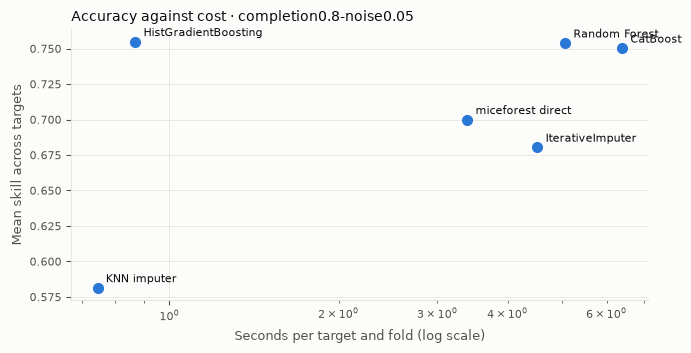

,method,warning_types,tasks,warning_example
0,IterativeImputer (10),ConvergenceWarning,5,[IterativeImputer] Early stopping criterion not reached.
1,IterativeImputer (30),ConvergenceWarning,5,[IterativeImputer] Early stopping criterion not reached.
2,IterativeImputer,ConvergenceWarning,2,[IterativeImputer] Early stopping criterion not reached.
3,miceforest PMM,PerformanceWarning,70,"DataFrame is highly fragmented. This is usually the result of calling `frame.insert` many times, which has poor performance. Consider joining all columns at once using pd.concat(axis=1) instead. To"
4,Joint miceforest PMM,PerformanceWarning,5,"DataFrame is highly fragmented. This is usually the result of calling `frame.insert` many times, which has poor performance. Consider joining all columns at once using pd.concat(axis=1) instead. To"


In [33]:
display(STUDY.cost.round(3))
fg.plot_cost(STUDY.cost, NUMERIC, REPRESENTATIVE, FIGURES)
with pd.option_context("display.max_colwidth", None):
    display(ev.warning_table(pd.concat([STUDY.tuning_log, STUDY.log], ignore_index=True)))


## 8. Findings

The text below is written from this run's tables, so it changes with the data. Changes refer to the same cells; "not clear" means the 95% row-bootstrap interval includes zero.

In [34]:
display(Markdown(ev.findings(NUMERIC, CATEGORY, PAIRS, STUDY.effects, GROUPS, STUDY.config)))


**Location and date**

- **x:** IterativeImputer, skill 96%, not clearly separated from Random Forest, whose MAE is 8.1% higher. MAE change on the same cells: noise 0 to 0.1 -4% (not clear), completeness 0.7 to 0.9 -87%. Skill runs from 49% (install_date missing · altitude missing) to 100% (install_date seen · altitude seen).
- **y:** IterativeImputer, skill 77%, not clearly separated from Random Forest, whose MAE is 0.2% higher. MAE change on the same cells: noise 0 to 0.1 -2%, completeness 0.7 to 0.9 -69%. Skill runs from -11% (x seen · altitude missing) to 100% (x seen · altitude seen).
- **install_date:** Random Forest, skill 95%, not clearly separated from HistGradientBoosting, whose MAE is 2.0% higher. MAE change on the same cells: noise 0 to 0.1 +12%, completeness 0.7 to 0.9 -68%. Skill runs from 77% (x missing · y seen) to 99% (x seen · y seen).
- **altitude:** Random Forest, skill 83%, not clearly separated from CatBoost, whose MAE is 0.2% higher. MAE change on the same cells: noise 0 to 0.1 +2%, completeness 0.7 to 0.9 -65%. Skill runs from 33% (x seen · y missing) to 96% (x seen · y seen).

**Field reading**

- **measured_humid:** CatBoost, skill 69%, not clearly separated from HistGradientBoosting, whose MAE is 0.4% higher. MAE change on the same cells: noise 0 to 0.1 +7%, completeness 0.7 to 0.9 -44%. Skill runs from 42% (measured_salt seen · measured_overgrowth missing) to 82% (measured_salt seen · measured_overgrowth seen).
- **measured_salt:** HistGradientBoosting, skill 54%, not clearly separated from Random Forest, whose MAE is 1.8% higher. MAE change on the same cells: noise 0 to 0.1 +14%, completeness 0.7 to 0.9 -39%. Skill runs from 10% (measured_humid seen · measured_overgrowth missing) to 72% (measured_humid seen · measured_overgrowth seen).
- **measured_overgrowth:** CatBoost, skill 80%, not clearly separated from HistGradientBoosting, whose MAE is 0.5% higher. MAE change on the same cells: noise 0 to 0.1 +20%, completeness 0.7 to 0.9 -61%. Skill runs from 52% (measured_humid missing · measured_salt missing) to 92% (measured_humid seen · measured_salt seen).

**Asset condition**

- **life:** CatBoost, skill 79%, practically tied with HistGradientBoosting, whose MAE is 3.6% higher. MAE change on the same cells: noise 0 to 0.1 +15%, completeness 0.7 to 0.9 -58%. Skill runs from 56% (model_id missing · measured_overgrowth missing) to 85% (model_id seen · measured_overgrowth seen).
- **measured_gas_a:** Random Forest, skill 87%, not clearly separated from HistGradientBoosting, whose MAE is 2.0% higher. MAE change on the same cells: noise 0 to 0.1 +50%, completeness 0.7 to 0.9 -36%. Skill runs from 73% (model_id missing · install_date missing) to 90% (model_id seen · install_date seen).
- **measured_gas_b:** Random Forest, skill 84%, not clearly separated from HistGradientBoosting, whose MAE is 0.5% higher. MAE change on the same cells: noise 0 to 0.1 +37%, completeness 0.7 to 0.9 -37%. Skill runs from 65% (model_id missing · install_date missing) to 89% (model_id seen · install_date seen).
- **measured_gas_c:** Random Forest, skill 84%, not clearly separated from HistGradientBoosting, whose MAE is 0.9% higher. MAE change on the same cells: noise 0 to 0.1 +42%, completeness 0.7 to 0.9 -36%. Skill runs from 66% (model_id missing · install_date missing) to 88% (model_id seen · install_date seen).
- **total_gas:** HistGradientBoosting, skill 81%, not clearly separated from CatBoost, whose MAE is 2.3% higher. MAE change on the same cells: noise 0 to 0.1 +78%, completeness 0.7 to 0.9 -18%. Skill runs from 77% (install_date missing · leakage missing) to 84% (install_date seen · leakage seen).
- **leakage:** Random Forest, skill 17%, not clearly separated from HistGradientBoosting, whose MAE is 0.1% higher. MAE change on the same cells: noise 0 to 0.1 +3%, completeness 0.7 to 0.9 -9%. Skill runs from 4% (total_gas missing · install_date missing) to 22% (total_gas seen · install_date seen).

**model_id**

- miceforest direct reaches 98.2% accuracy against 28.1% for the mode, and at least 93.3% in every scenario.

**Negative control**

- 0 of 54 comparisons with the median favour a method and 23 favour the median. The largest skill reached is 0.1%. With this many comparisons, about 1 would favour a method by chance alone at the 95% level.

### Limits

- The data is synthetic, and missingness is completely at random. Real gaps are likely to depend on the asset, which this study does not test.
- There is one generated truth table, so the study does not measure variation between generated datasets.
- Settings are tuned on one scenario and may not be the best elsewhere. Tuning covers a sample of settings, so it does not establish any method's ceiling.
- The joint model is not tuned, so it is compared at its earlier settings.
- Row intervals are conditional on fitted models. Neighbouring grid rows are related, so intervals may be narrower than they should be.
- `life`, `total_gas` and `leakage` are exact by design, so results for and from these columns are better than noisy measurements would allow.

In [35]:
completed = ev.export_completions(SCORED, STUDY.measured[REPRESENTATIVE], REPRESENTATIVE, Path(STUDY.directory) / "completed")
display(completed)
display(ev.run_summary(STUDY.log, PLAN))
print("Run folder:", STUDY.directory)
print("To resume this run, set RESUME_RUN_ID to:", Path(STUDY.directory).name)


,method,file,cells still missing
0,Median,Median.csv,0
1,KNN imputer,KNN_imputer.csv,0
2,IterativeImputer,IterativeImputer.csv,1965
3,Random Forest,Random_Forest.csv,0
4,HistGradientBoosting,HistGradientBoosting.csv,0
5,CatBoost,CatBoost.csv,0
6,miceforest direct,miceforest_direct.csv,0


,planned tasks,finished tasks,succeeded,failed,tasks with warnings
0,7875,7875,7875,0,87


Run folder: C:\Users\Morgan\Desktop\Capstone Project\gh\team19-asset-data\outputs\imputation-study\runs\20261105-133845
To resume this run, set RESUME_RUN_ID to: 20261105-133845
